# Microproyecto 1 — Generación de bocetos con redes recurrentes (Sketch-RNN)

**Curso:** Modelos Avanzados de Procesamiento de Lenguaje Natural  
**Equipo:** Equipo 21

**Integrantes:**

1. Juan Javier Valera Mejias
2. Juan David Villalba Guavita
3. Juan Felipe Rodriguez Granados
4. Leidy Dayana Vega Medina

**Categoría seleccionada:** `fish` (pez), dataset Quick, Draw!  
**Fecha:** 19 de octubre de 2026

## 1. Portada e introducción

### Resumen del proyecto

En este notebook se implementa y entrena desde cero, en PyTorch, un modelo autorregresivo que genera bocetos de la
categoría `fish` del dataset Quick, Draw!. Cada boceto es una secuencia de puntos del lápiz. A partir de los puntos
anteriores, el modelo predice el siguiente punto con dos salidas numéricas (los desplazamientos Δx y Δy, un problema
de regresión) y una salida categórica (el estado del lápiz, con tres clases). Las dos salidas se entrenan con una
función de pérdida compuesta. Una vez entrenado, el modelo genera bocetos nuevos punto a punto: cada punto generado
se vuelve la entrada del paso siguiente.

Se trabajó con 16.000 bocetos de entrenamiento, 2.000 de validación y 2.000 de prueba, tomados de los conjuntos
`train`, `valid` y `test` del archivo `.npz`, con un máximo de 200 puntos por boceto.

Antes de fijar el modelo se compararon 39 configuraciones en tres rondas (sección 7.2): seis familias de modelos
secuenciales (RNN simple, GRU, LSTM, Transformer causal, TCN causal y un MLP con ventana fija), tres formas de modelar
Δx y Δy (regresión MSE, Gaussiana bivariada y mezcla de Gaussianas), dos variantes del modelo recurrente y varios
hiperparámetros de la pérdida y del entrenamiento. Todas las decisiones se tomaron con el conjunto de validación; el
de prueba solo se usó al final.

El modelo final combina dos capas convolucionales causales con una LSTM de 512 unidades. Para Δx y Δy predice una
mezcla de Gaussianas y para el estado del lápiz, los logits de sus tres clases.

| Métrica en prueba | Resultado |
|---|---:|
| MSE de (Δx, Δy), coordenadas normalizadas | 0.4560 |
| MSE de (Δx, Δy), en píxeles² | 882.5 |
| F1 macro de los tres estados (argmax) | 0.6702 |
| F1 macro con umbrales calibrados en validación | 0.6781 |
| Pérdida compuesta | 1.5250 |

Las métricas se calcularon sobre los 2.000 bocetos de prueba (76.135 puntos reales), con predicción a un paso.

### Diagrama de la arquitectura

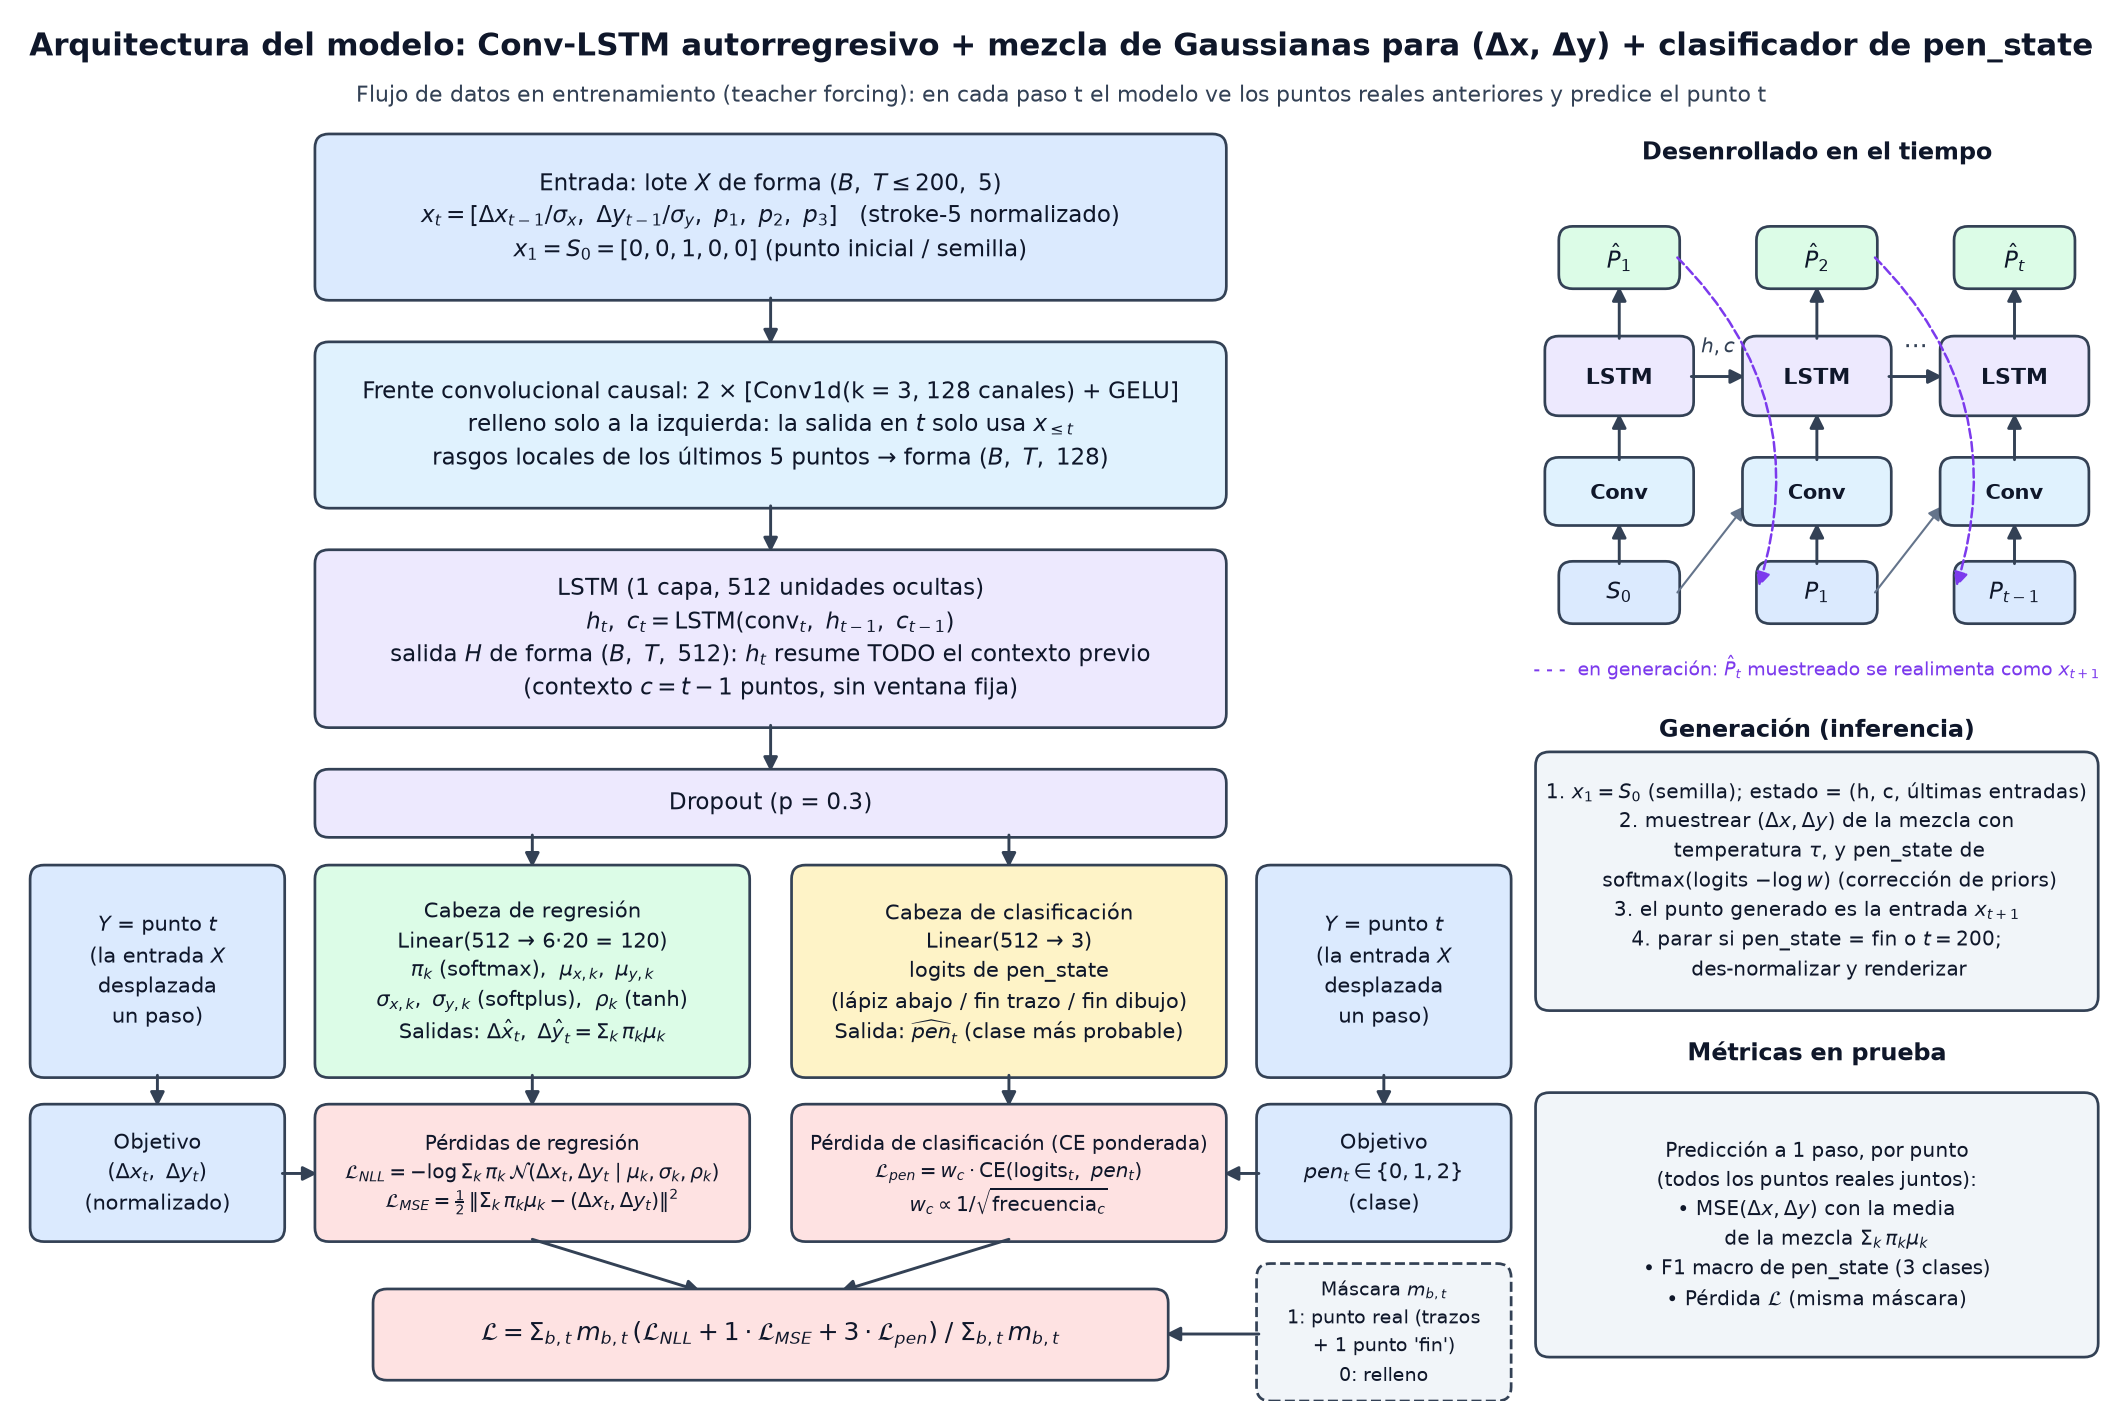

### Explicación de la arquitectura

El modelo recibe lotes de secuencias de tamaño `(B, T, 5)`, con `T ≤ 200`. Cada posición tiene cinco valores:

`[delta_x, delta_y, lápiz abajo, fin de trazo, fin de dibujo]`

Los desplazamientos están normalizados con la desviación estándar de entrenamiento y los tres últimos valores
codifican el estado del lápiz en one-hot. La entrada es la secuencia real desplazada un paso y precedida por un punto
inicial `S0 = (0, 0, 1, 0, 0)`. Así, para predecir el punto `t` el modelo usa como contexto los puntos `1 … t-1`
(teacher forcing).

1. Frente convolucional causal: dos capas `Conv1d` con kernel 3, 128 canales y activación GELU. El relleno se aplica
   solo a la izquierda, de modo que la salida en `t` depende únicamente de las entradas hasta `t`. Cada posición ve
   los últimos 5 puntos y extrae rasgos locales del trazo, como la dirección, la curvatura o un cambio de trazo.
2. LSTM: una capa de 512 unidades sobre esos rasgos. Su estado `(h_t, c_t)` resume todo lo dibujado hasta el
   momento, sin ventana fija: qué partes del pez ya están, cuántos trazos van y si el contorno ya se cerró.
3. Dropout con p = 0.3 sobre los estados ocultos.
4. Cabeza de regresión, `Linear(512, 120)`: produce los parámetros de una mezcla de 20 Gaussianas bivariadas para
   `(Δx, Δy)`: pesos `π_k` (softmax), medias `μ_k`, desviaciones `σ_k` (softplus más un valor mínimo) y correlaciones
   `ρ_k` (tanh). La media de la mezcla, `Σ_k π_k μ_k`, es la predicción puntual que se usa para el MSE; al generar se
   muestrea la mezcla completa.
5. Cabeza de clasificación, `Linear(512, 3)`: logits de los tres estados del lápiz.
6. Pérdida compuesta: `L = NLL + 1·MSE + 3·CE`, promediada sobre los puntos reales. NLL es la log-verosimilitud
   negativa de la mezcla, MSE es el error cuadrático de su media y CE es la entropía cruzada del estado del lápiz,
   ponderada con pesos ∝ 1/√frecuencia para que los estados poco frecuentes tengan más peso. Una máscara excluye el
   relleno.
7. Generación: se parte de `S0` y en cada paso se muestrea `(Δx, Δy)` de la mezcla, con temperatura `τ`, y el estado
   del lápiz de `softmax(logits − log w)`. Restar el logaritmo de los pesos de clase compensa la ponderación usada en
   el entrenamiento. El punto generado se usa como siguiente entrada hasta que el modelo predice fin de dibujo o se
   alcanzan 200 puntos.

### Justificación de la selección

La arquitectura se eligió a partir de los experimentos de la sección 7.2. La tabla resume las configuraciones más
representativas, todas entrenadas durante 15 épocas y evaluadas en validación:

| Modelo | Salida (Δx, Δy) | Pérdida val | MSE val | F1 macro val (calibrado) | Bocetos generados |
|---|---|---:|---:|---:|---|
| LSTM-256 | MSE | n/c | 0.510 | 0.632 | Todos iguales, una "U" promedio |
| LSTM-256 | Gaussiana bivariada | n/c | 0.701 | 0.631 | Trazos ruidosos |
| LSTM-256 | Mezcla de Gaussianas | 0.894 | 0.640 | 0.592 | Variados, contornos incompletos |
| RNN simple-256 | Mezcla de Gaussianas | 0.920 | 0.612 | 0.586 | |
| GRU-256 | Mezcla de Gaussianas | 0.914 | 0.649 | 0.589 | |
| LSTM-512 | Mezcla de Gaussianas | 0.748 | 0.567 | 0.607 | Algunos peces reconocibles |
| Transformer causal (4 capas) | Mezcla de Gaussianas | 0.780 | 0.656 | 0.590 | |
| MLP con ventana c = 16 | Mezcla de Gaussianas | 0.852 | 0.634 | 0.571 | |
| TCN causal (campo receptivo 125) | Mezcla de Gaussianas | 0.544 | 0.556 | 0.623 | Peces reconocibles |
| Conv + LSTM-256 | Mezcla de Gaussianas | 0.603 | 0.578 | 0.609 | |
| Conv + LSTM-512 | Mezcla de Gaussianas | 0.501 | 0.532 | 0.620 | La mayoría, peces reconocibles |

n/c: no comparable, porque esas variantes optimizan otra pérdida. Las muestras generadas por cada corrida están en la
carpeta `experimentos/`.

- Se necesitaba un modelo secuencial causal con memoria de todo el boceto, porque el siguiente punto depende de lo ya
  dibujado (cerrar el cuerpo, agregar la cola, decidir si el dibujo terminó). Los modelos con ventana fija quedaron
  por debajo y, entre los recurrentes, la LSTM superó a la RNN simple y a la GRU del mismo tamaño. El Transformer
  causal no mejoró a la LSTM con estos datos y fue el más lento en CPU.
- La TCN causal le ganó a la LSTM pura, lo que indicaba que a la LSTM le faltaban rasgos locales de los últimos
  puntos. Por eso se agregaron dos capas `Conv1d` causales antes de la LSTM: la pérdida de validación bajó de 0.894 a
  0.603 con LSTM-256 y de 0.748 a 0.501 con LSTM-512, por debajo de la TCN (0.544). Agregar la posición absoluta del
  lápiz como entrada no ayudó.
- Para Δx y Δy se eligió la mezcla de Gaussianas. Con regresión MSE el modelo aprende el promedio de las posibles
  direcciones del trazo y, al generar, todos los bocetos terminan siendo la misma forma en "U". Una sola Gaussiana
  tampoco alcanza. Con la mezcla los bocetos son variados y su media sigue siendo una buena predicción puntual.
- La pérdida se ajustó en la ronda 2: el término MSE sobre la media de la mezcla bajó el MSE de validación de 0.578 a
  0.500, los pesos de clase subieron el F1 macro de 0.333 a 0.610 y `w_pen = 3` mejoró la separación de los estados
  del lápiz. La combinación de los tres fue la mejor (MSE 0.499, F1 0.636). En el entrenamiento, el cambio más
  importante fue usar una tasa de aprendizaje de 0.002.
- El tamaño final y la regularización se escogieron en la ronda 3, con entrenamiento largo y early stopping.

## 2. Librerías

El modelo se implementa con PyTorch usando capas estándar (`nn.Conv1d`, `nn.LSTM`, `nn.Linear`, `nn.Dropout`).
NumPy y pandas se usan para manipular los datos, Matplotlib para las gráficas y los bocetos, y scikit-learn solo para
las métricas (F1 macro, MSE y matriz de confusión).

In [1]:
import copy
import math
import os
import random
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             f1_score, mean_squared_error)
from torch.utils.data import DataLoader, Dataset, Sampler

SEED = 42


def set_seed(seed=SEED):
    """Fija las semillas de Python, NumPy y PyTorch para que el notebook sea reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
print(f"PyTorch {torch.__version__} | NumPy {np.__version__} | dispositivo: {DEVICE} | "
      f"hilos CPU: {torch.get_num_threads()}")

PyTorch 2.14.0+cpu | NumPy 2.4.4 | dispositivo: cpu | hilos CPU: 14


## 3. Lectura del dataset y exploración

Descargamos la versión sketch-rnn de la categoría `fish`. El archivo `.npz` ya viene dividido en `train` (70.000
bocetos), `valid` (2.500) y `test` (2.500), y sus bocetos están simplificados con el algoritmo RDP. Cada boceto es un
arreglo de tamaño `(N_puntos, 3)` en formato stroke-3: `(Δx, Δy, pen_lift)`.

In [2]:
CATEGORY = "fish"
MAX_POINTS = 200                       # límite obligatorio de puntos por boceto
N_TRAIN, N_VALID, N_TEST = 16_000, 2_000, 2_000

url = f"https://storage.googleapis.com/quickdraw_dataset/sketchrnn/{CATEGORY}.npz"
npz_path = f"{CATEGORY}.npz"
if not os.path.exists(npz_path):
    urllib.request.urlretrieve(url, npz_path)

with warnings.catch_warnings():        # NumPy >= 2.4 emite un aviso de formato al leer el pickle
    warnings.simplefilter("ignore")
    data = np.load(npz_path, encoding="latin1", allow_pickle=True)
    train_sketches, valid_sketches, test_sketches = data["train"], data["valid"], data["test"]

print(f"train: {len(train_sketches):,} | valid: {len(valid_sketches):,} | test: {len(test_sketches):,}")
sketch = train_sketches[0]
print("Forma del dibujo:", sketch.shape, "| dtype:", sketch.dtype)
print(sketch[:5])

train: 70,000 | valid: 2,500 | test: 2,500
Forma del dibujo: (24, 3) | dtype: int16
[[  0 106   0]
 [  5  28   0]
 [ 26 -30   0]
 [ 25 -23   0]
 [ 28 -20   0]]


Para visualizar los bocetos usamos la función guía del enunciado: los desplazamientos se convierten en posiciones
absolutas con una suma acumulada y cada trazo se dibuja hasta el punto con `pen_lift = 1`. La separamos en dos
funciones: `draw_sketch`, que dibuja sobre un eje y sirve para las grillas, y `render_sketch`, que guarda el PNG.

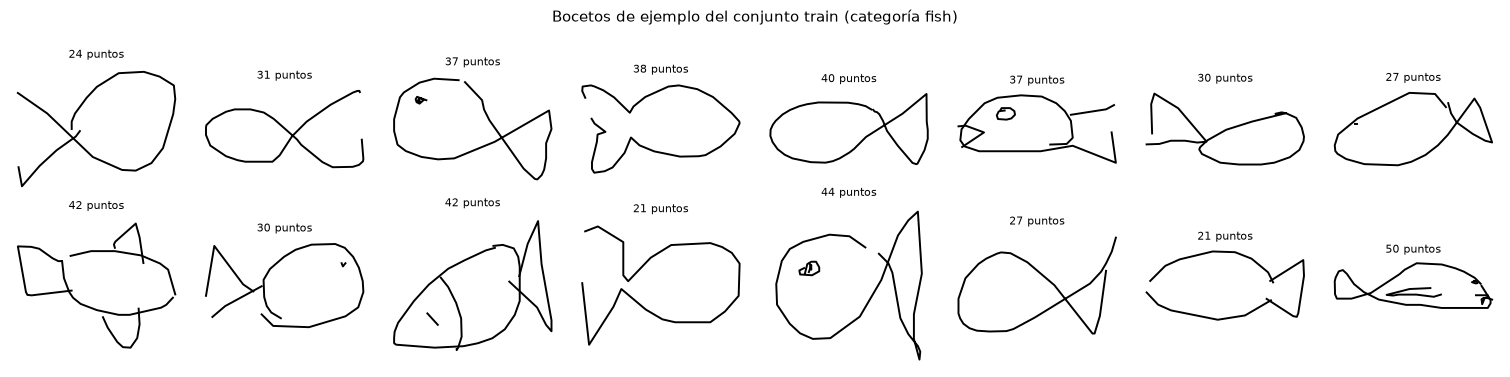

In [3]:
def draw_sketch(ax, sketch, lw=2.0, color="black"):
    """Dibuja un boceto stroke-3 (dx, dy, pen_lift) sobre un eje de Matplotlib."""
    coords = np.cumsum(sketch[:, :2], axis=0)
    start = 0
    for i in range(len(sketch)):
        if sketch[i, 2] == 1:                                  # fin de un trazo
            ax.plot(coords[start:i + 1, 0], -coords[start:i + 1, 1], color=color, linewidth=lw)
            start = i + 1
    ax.set_aspect("equal")
    ax.axis("off")


def render_sketch(sketch, filename):
    """Guarda un boceto stroke-3 como PNG (fragmento guía del enunciado)."""
    fig, ax = plt.subplots()
    draw_sketch(ax, sketch)
    fig.savefig(filename, bbox_inches="tight")
    plt.close(fig)


def show_grid(sketches, ncols=8, titles=None, size=1.9, lw=1.4, suptitle=None):
    nrows = math.ceil(len(sketches) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows))
    for k, ax in enumerate(np.ravel(axes)):
        if k < len(sketches):
            draw_sketch(ax, sketches[k], lw=lw)
            if titles is not None:
                ax.set_title(titles[k], fontsize=8)
        else:
            ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.tight_layout()
    plt.show()


show_grid(list(train_sketches[:16]), titles=[f"{len(s)} puntos" for s in train_sketches[:16]],
          suptitle="Bocetos de ejemplo del conjunto train (categoría fish)")

Ahora revisamos la distribución de longitudes, trazos y desplazamientos.

,count,mean,std,min,25%,50%,75%,max,> 199 puntos
train,70000.0,37.1,12.6,19.0,27.0,34.0,44.0,75.0,0
valid,2500.0,36.9,12.6,19.0,27.0,34.0,44.0,75.0,0
test,2500.0,37.0,12.7,19.0,27.0,34.0,44.0,75.0,0


Trazos por boceto (train): media 3.20, mediana 3, máx 25
Fracción de puntos con pen_lift = 1: 0.086
Δx: media 1.15, std 51.76, rango [-1599, 1483] | Δy: media 0.63, std 35.42, rango [-630, 684]


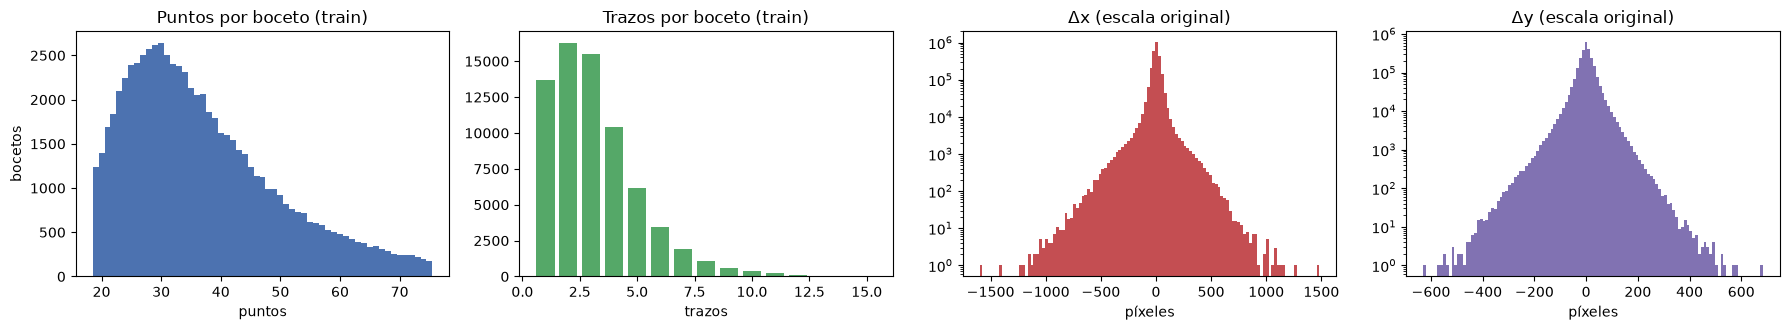

In [4]:
lengths_raw = {"train": np.array([len(s) for s in train_sketches]),
               "valid": np.array([len(s) for s in valid_sketches]),
               "test": np.array([len(s) for s in test_sketches])}
summary = pd.DataFrame({k: pd.Series(v).describe() for k, v in lengths_raw.items()}).T.round(1)
summary[f"> {MAX_POINTS - 1} puntos"] = [int((v > MAX_POINTS - 1).sum()) for v in lengths_raw.values()]
display(summary)

n_strokes = np.array([int(s[:, 2].sum()) for s in train_sketches])
points = np.concatenate([s for s in train_sketches]).astype(np.float32)
print(f"Trazos por boceto (train): media {n_strokes.mean():.2f}, mediana {np.median(n_strokes):.0f}, "
      f"máx {n_strokes.max()}")
print(f"Fracción de puntos con pen_lift = 1: {points[:, 2].mean():.3f}")
print(f"Δx: media {points[:, 0].mean():.2f}, std {points[:, 0].std():.2f}, rango [{points[:, 0].min():.0f}, "
      f"{points[:, 0].max():.0f}] | Δy: media {points[:, 1].mean():.2f}, std {points[:, 1].std():.2f}, "
      f"rango [{points[:, 1].min():.0f}, {points[:, 1].max():.0f}]")

fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
axes[0].hist(lengths_raw["train"], bins=np.arange(lengths_raw["train"].min(), lengths_raw["train"].max() + 2) - 0.5,
             color="#4c72b0")
axes[0].set(title="Puntos por boceto (train)", xlabel="puntos", ylabel="bocetos")
vals, cnts = np.unique(n_strokes, return_counts=True)
axes[1].bar(vals[vals <= 15], cnts[vals <= 15], color="#55a868")
axes[1].set(title="Trazos por boceto (train)", xlabel="trazos")
axes[2].hist(points[:, 0], bins=120, color="#c44e52", log=True)
axes[2].set(title="Δx (escala original)", xlabel="píxeles")
axes[3].hist(points[:, 1], bins=120, color="#8172b2", log=True)
axes[3].set(title="Δy (escala original)", xlabel="píxeles")
plt.tight_layout()
plt.show()

Como se puede observar:

- Los bocetos de pez son cortos: 37 puntos en promedio y como máximo 75. Tienen pocos trazos (alrededor de 3):
  normalmente el cuerpo y la cola en uno o dos trazos, y a veces el ojo o las aletas. Ningún boceto supera los 200
  puntos, así que el truncado obligatorio no elimina información, aunque igual se implementa.
- Δx y Δy tienen escalas distintas (desviaciones de 52 y 35 píxeles aproximadamente), colas largas y media cercana a
  cero. Por eso conviene normalizarlos dividiendo por su desviación estándar, como sugiere el enunciado.
- El estado del lápiz está muy desbalanceado: la gran mayoría de los puntos tienen el lápiz abajo, cerca del 8 % son
  fin de trazo y solo hay un fin de dibujo por boceto. Esto hace que el F1 macro sea la métrica adecuada para la
  clasificación.

## 4. Preprocesamiento

### 4.1 De stroke-3 a stroke-5

Cada punto se convierte a `(Δx, Δy, p1, p2, p3)`, donde el estado del lápiz es una variable categórica de tres clases
codificada en one-hot:

| Clase | One-hot | Significado |
|---|---|---|
| 0 | `p1 = 1` | El lápiz toca el papel: se dibuja una línea hasta el siguiente punto |
| 1 | `p2 = 1` | El lápiz se levanta después de este punto (fin de trazo) |
| 2 | `p3 = 1` | El dibujo terminó: este punto y los siguientes no se dibujan |

Al final de cada boceto agregamos un punto de fin de dibujo, `(0, 0, 0, 0, 1)`. Sin ese punto el modelo nunca vería
la clase 2 dentro de la máscara y no aprendería a detenerse. Para respetar el límite de 200 puntos, contando ese punto
final, cada secuencia se trunca a 199 puntos antes de agregarlo.

In [5]:
START_TOKEN = np.array([0, 0, 1, 0, 0], dtype=np.float32)   # S0: punto inicial (semilla)
END_TOKEN = np.array([0, 0, 0, 0, 1], dtype=np.float32)     # fin de dibujo (también es el relleno)
CLASS_NAMES = ["lápiz abajo", "fin de trazo", "fin de dibujo"]


def to_stroke5(sketch3, max_points=MAX_POINTS):
    """stroke-3 (dx, dy, pen_lift) -> stroke-5 (dx, dy, p1, p2, p3) truncado + punto de fin."""
    s3 = np.asarray(sketch3, dtype=np.float32)[: max_points - 1]
    n = len(s3)
    s5 = np.zeros((n + 1, 5), dtype=np.float32)
    s5[:n, 0:2] = s3[:, 0:2]
    s5[:n, 3] = s3[:, 2]              # p2 = pen_lift
    s5[:n, 2] = 1.0 - s3[:, 2]        # p1 = 1 - pen_lift
    s5[n - 1, 2:4] = [0.0, 1.0]       # el último trazo siempre se cierra (importa si se truncó)
    s5[n] = END_TOKEN                 # punto explícito de fin de dibujo
    return s5


def to_stroke3(sketch5):
    """Inversa (para renderizar): descarta el punto de fin y vuelve a (dx, dy, pen_lift)."""
    s5 = sketch5[sketch5[:, 4] == 0]
    s3 = np.zeros((len(s5), 3), dtype=np.float32)
    s3[:, 0:2] = s5[:, 0:2]
    s3[:, 2] = s5[:, 3]
    if len(s3):
        s3[-1, 2] = 1.0
    return s3


example5 = to_stroke5(train_sketches[0])
print("stroke-3 (primeros 3 puntos):\n", train_sketches[0][:3])
print("stroke-5 (primeros 3 puntos):\n", example5[:3])
print("stroke-5 (últimos 2 puntos: último punto de trazo y fin de dibujo):\n", example5[-2:])
assert np.allclose(to_stroke3(example5), train_sketches[0]), "la conversión debe ser reversible"

stroke-3 (primeros 3 puntos):
 [[  0 106   0]
 [  5  28   0]
 [ 26 -30   0]]
stroke-5 (primeros 3 puntos):
 [[  0. 106.   1.   0.   0.]
 [  5.  28.   1.   0.   0.]
 [ 26. -30.   1.   0.   0.]]
stroke-5 (últimos 2 puntos: último punto de trazo y fin de dibujo):
 [[ 0. 11.  0.  1.  0.]
 [ 0.  0.  0.  0.  1.]]


### 4.2 Normalización

Δx y Δy se dividen por su desviación estándar, calculada por eje y únicamente con los puntos de trazo de entrenamiento
(en la sección 5), para no usar información de validación ni de prueba. No restamos la media, para que un
desplazamiento nulo siga valiendo 0 (el punto inicial y el punto de fin usan Δ = 0). La normalización se revierte al
generar.

### 4.3 Truncado, relleno, máscara y pares entrada–objetivo

Cada secuencia se guarda en un tensor de longitud fija 200 y las posiciones sobrantes se rellenan con el estado de
fin de dibujo. También guardamos la longitud real `L` (puntos de trazo más el punto de fin) para construir la máscara
`m_t = 1 si t < L`. Con esa máscara el relleno no entra ni en la pérdida ni en las métricas.

Para predecir el siguiente punto, la entrada se desplaza un paso: `X = [S0, P1, …, P199]` y `Y = [P1, …, P200]`, donde
`S0 = (0, 0, 1, 0, 0)` es el punto inicial. Así, en el paso `t` el modelo ve `S0, P1, …, P(t-1)` y debe predecir `Pt`.

In [6]:
def normalize(sketch5, scale):
    out = sketch5.copy()
    out[:, 0:2] /= scale
    return out


def denormalize(sketch5, scale):
    out = sketch5.copy()
    out[:, 0:2] *= scale
    return out


def build_tensors(sketches5, scale, max_points=MAX_POINTS):
    """Lista de bocetos stroke-5 -> (X, Y, L): entradas, objetivos (N, 200, 5) y longitudes reales (N,)."""
    n = len(sketches5)
    full = np.tile(END_TOKEN, (n, max_points + 1, 1))         # relleno = estado "fin de dibujo"
    full[:, 0] = START_TOKEN
    lengths = np.zeros(n, dtype=np.int64)
    for i, s5 in enumerate(sketches5):
        L = len(s5)
        full[i, 1:L + 1] = normalize(s5, scale)
        lengths[i] = L
    X = torch.from_numpy(full[:, :-1].copy())                 # [S0, P1, ..., P199]
    Y = torch.from_numpy(full[:, 1:].copy())                  # [P1, ..., P200]
    return X, Y, torch.from_numpy(lengths)


def make_mask(lengths, T):
    """Máscara booleana (B, T): True en los puntos reales, False en el relleno."""
    return torch.arange(T, device=lengths.device)[None, :] < lengths[:, None]


Xe, Ye, Le = build_tensors([example5], scale=np.ones(2, dtype=np.float32))
me = make_mask(Le, MAX_POINTS)
print(f"X: {tuple(Xe.shape)} | Y: {tuple(Ye.shape)} | longitud real L = {Le.item()} | "
      f"puntos enmascarados = {int((~me).sum())}")
print("Entrada X[0, :3] (S0, P1, P2):\n", Xe[0, :3].numpy())
print("Objetivo Y[0, :3] (P1, P2, P3):\n", Ye[0, :3].numpy())
print("Último punto real y primer relleno en Y:\n", Ye[0, Le.item() - 1:Le.item() + 1].numpy())

X: (1, 200, 5) | Y: (1, 200, 5) | longitud real L = 25 | puntos enmascarados = 175
Entrada X[0, :3] (S0, P1, P2):
 [[  0.   0.   1.   0.   0.]
 [  0. 106.   1.   0.   0.]
 [  5.  28.   1.   0.   0.]]
Objetivo Y[0, :3] (P1, P2, P3):
 [[  0. 106.   1.   0.   0.]
 [  5.  28.   1.   0.   0.]
 [ 26. -30.   1.   0.   0.]]
Último punto real y primer relleno en Y:
 [[0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


## 5. Split train / validación / prueba

Se aplica el split obligatorio de 20.000 bocetos (80/10/10), respetando los conjuntos originales del `.npz`: 16.000
bocetos de `train`, 2.000 de `valid` y 2.000 de `test`, elegidos aleatoriamente sin reemplazo con semilla 42. Después
calculamos la escala de normalización solo con entrenamiento y construimos los tensores con relleno y máscara de cada
conjunto.

- Entrenamiento: se usa para ajustar los pesos del modelo.
- Validación: se usa para elegir hiperparámetros, aplicar early stopping y vigilar el sobreajuste.
- Prueba: se reserva para la evaluación final de la sección 8.

In [7]:
rng = np.random.default_rng(SEED)


def take_subset(sketches, n):
    idx = rng.choice(len(sketches), size=n, replace=False)
    return [sketches[i] for i in idx]


train3 = take_subset(train_sketches, N_TRAIN)
valid3 = take_subset(valid_sketches, N_VALID)
test3 = take_subset(test_sketches, N_TEST)
n_trunc = sum(len(s) > MAX_POINTS - 1 for s in train3 + valid3 + test3)
print(f"Bocetos: train {len(train3):,} | valid {len(valid3):,} | test {len(test3):,} | "
      f"total {len(train3) + len(valid3) + len(test3):,} | truncados a 200 puntos: {n_trunc}")

train5 = [to_stroke5(s) for s in train3]
valid5 = [to_stroke5(s) for s in valid3]
test5 = [to_stroke5(s) for s in test3]

# escala de normalización: desviación estándar por eje de los puntos de trazo de TRAIN
train_points = np.concatenate([s[:-1, 0:2] for s in train5])
SCALE = train_points.std(axis=0).astype(np.float32)
print(f"Escala de normalización (std de train): Δx = {SCALE[0]:.3f}, Δy = {SCALE[1]:.3f}")

X_train, Y_train, L_train = build_tensors(train5, SCALE)
X_valid, Y_valid, L_valid = build_tensors(valid5, SCALE)
X_test, Y_test, L_test = build_tensors(test5, SCALE)
for name, (X, L) in {"train": (X_train, L_train), "valid": (X_valid, L_valid), "test": (X_test, L_test)}.items():
    print(f"{name:5s}: X {tuple(X.shape)} | puntos reales {int(L.sum()):,} | L media {L.float().mean():.1f} | "
          f"L máx {int(L.max())}")

mask_train = make_mask(L_train, MAX_POINTS)
classes_train = Y_train[..., 2:].argmax(-1)[mask_train]
freq = torch.bincount(classes_train, minlength=3).float() / len(classes_train)
display(pd.DataFrame({"clase": CLASS_NAMES, "frecuencia en train": freq.numpy().round(4)}))

Bocetos: train 16,000 | valid 2,000 | test 2,000 | total 20,000 | truncados a 200 puntos: 0
Escala de normalización (std de train): Δx = 51.573, Δy = 35.501


train: X (16000, 200, 5) | puntos reales 610,432 | L media 38.2 | L máx 76
valid: X (2000, 200, 5) | puntos reales 75,896 | L media 37.9 | L máx 76
test : X (2000, 200, 5) | puntos reales 76,135 | L media 38.1 | L máx 76


,clase,frecuencia en train
0,lápiz abajo,0.8903
1,fin de trazo,0.0834
2,fin de dibujo,0.0262


Como los bocetos tienen longitudes muy distintas, definimos un `Sampler` que arma cada lote con bocetos de longitud
parecida y luego recorta el lote a su longitud real máxima. El orden de los lotes sigue siendo aleatorio en cada
época. Esto no cambia los resultados, porque el relleno está enmascarado y el modelo es causal, pero reduce bastante
el tiempo de entrenamiento en CPU.

In [8]:
class SketchDataset(Dataset):
    def __init__(self, X, Y, L):
        self.X, self.Y, self.L = X, Y, L

    def __len__(self):
        return len(self.L)

    def __getitem__(self, i):
        return self.X[i], self.Y[i], self.L[i]


class BucketBatchSampler(Sampler):
    """Lotes de bocetos de longitud similar; el orden de los lotes es aleatorio en cada época."""

    def __init__(self, lengths, batch_size, shuffle=True, pool=32, seed=SEED):
        self.lengths = lengths.numpy()
        self.batch_size, self.shuffle, self.pool = batch_size, shuffle, pool
        self.rng = np.random.default_rng(seed)

    def __iter__(self):
        n, bs = len(self.lengths), self.batch_size
        if not self.shuffle:
            order = np.argsort(self.lengths, kind="stable")
            yield from (order[i:i + bs].tolist() for i in range(0, n, bs))
            return
        perm, batches = self.rng.permutation(n), []
        for s in range(0, n, bs * self.pool):
            chunk = perm[s:s + bs * self.pool]
            chunk = chunk[np.argsort(self.lengths[chunk], kind="stable")]
            batches += [chunk[i:i + bs].tolist() for i in range(0, len(chunk), bs)]
        for k in self.rng.permutation(len(batches)):
            yield batches[k]

    def __len__(self):
        return math.ceil(len(self.lengths) / self.batch_size)


def collate_trim(batch):
    """Apila el lote y lo recorta a la longitud real máxima del lote."""
    X, Y, L = map(torch.stack, zip(*batch))
    T = int(L.max())
    return X[:, :T], Y[:, :T], L


def make_loader(X, Y, L, batch_size, shuffle):
    return DataLoader(SketchDataset(X, Y, L), batch_sampler=BucketBatchSampler(L, batch_size, shuffle),
                      collate_fn=collate_trim)

## 6. Arquitectura y creación del modelo

A continuación se implementa en PyTorch la arquitectura del diagrama de la sección 1, con los hiperparámetros elegidos
en la sección 7.2:

- Frente convolucional causal (`nn.Conv1d` con relleno a la izquierda y GELU): extrae rasgos locales de los últimos
  puntos. La salida en el paso `t` solo depende de las entradas hasta `t`.
- `nn.LSTM` (batch_first): integra esos rasgos a lo largo de la secuencia. Su estado `(h, c)` guarda la información de
  todo lo dibujado.
- `nn.Dropout` sobre los estados ocultos.
- Cabeza de regresión `nn.Linear(H, 6·M)`: parámetros de la mezcla de `M` Gaussianas bivariadas (pesos, medias,
  desviaciones y correlación).
- Cabeza de clasificación `nn.Linear(H, 3)`: logits del estado del lápiz.

El método `forward` recibe un estado opcional (el estado de la LSTM y los últimos puntos que necesita el frente
convolucional). Así se puede generar paso a paso con el mismo cálculo que en el entrenamiento; al final de la celda
comprobamos que ambos modos dan el mismo resultado.

In [9]:
HP = dict(
    conv_channels=128,        # canales del frente convolucional
    conv_layers=2,            # capas Conv1d causales
    kernel_size=3,            # tamaño del kernel de cada Conv1d
    hidden_size=512,          # unidades ocultas del LSTM
    num_layers=1,             # capas del LSTM
    dropout=0.3,              # dropout sobre los estados ocultos
    n_mix=20,                 # componentes de la mezcla de Gaussianas
    w_mse=1.0,                # peso del término MSE de la media de la mezcla
    w_pen=3.0,                # peso de la entropía cruzada de pen_state
    lr=0.002,                 # tasa de aprendizaje inicial (Adam)
    augment=0.0,              # aumento de datos: escalado aleatorio ±augment (0 = sin aumento)
    batch_size=128,           # bocetos por lote
    epochs=60,                # máximo de épocas
    patience=8,               # early stopping: épocas sin mejorar en validación
    lr_patience=3,            # épocas sin mejorar antes de reducir la tasa de aprendizaje a la mitad
    clip=1.0,                 # norma máxima del gradiente (gradient clipping)
    temperature=0.3,          # temperatura de muestreo de la mezcla al generar
    png_seed=2026,            # semilla de los 3 bocetos PNG entregables
)


class CausalConv1d(nn.Module):
    """Conv1d causal: rellena solo a la izquierda, de modo que la salida en t solo ve entradas <= t."""

    def __init__(self, in_channels, out_channels, kernel_size):
        super().__init__()
        self.pad = kernel_size - 1
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size)

    def forward(self, x):                                       # x: (B, C, T)
        return self.conv(F.pad(x, (self.pad, 0)))


class SketchConvLSTM(nn.Module):
    """Frente Conv1d causal + LSTM + mezcla de Gaussianas para (Δx, Δy) + clasificador de pen_state."""

    def __init__(self, conv_channels=HP["conv_channels"], conv_layers=HP["conv_layers"],
                 kernel_size=HP["kernel_size"], hidden_size=HP["hidden_size"], num_layers=HP["num_layers"],
                 dropout=HP["dropout"], n_mix=HP["n_mix"]):
        super().__init__()
        self.n_mix = n_mix
        convs, c_in = [], 5
        for _ in range(conv_layers):
            convs += [CausalConv1d(c_in, conv_channels, kernel_size), nn.GELU()]
            c_in = conv_channels
        self.conv = nn.Sequential(*convs)
        self.receptive = conv_layers * (kernel_size - 1)        # puntos previos extra que ve el frente conv
        self.lstm = nn.LSTM(input_size=conv_channels, hidden_size=hidden_size, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.gmm_head = nn.Linear(hidden_size, 6 * n_mix)      # π, μx, μy, σx, σy, ρ por componente
        self.pen_head = nn.Linear(hidden_size, 3)              # logits de pen_state

    def forward(self, x, state=None):
        """x: (B, T, 5). state = (estado del LSTM, últimas entradas) solo se usa al generar paso a paso."""
        lstm_state, past = (None, None) if state is None else state
        x_ext = x if past is None else torch.cat([past, x], dim=1)
        feats = self.conv(x_ext.transpose(1, 2)).transpose(1, 2)[:, -x.size(1):]   # (B, T, C)
        h, lstm_state = self.lstm(feats, lstm_state)                               # (B, T, H)
        h = self.dropout(h)
        return self.gmm_head(h), self.pen_head(h), (lstm_state, x_ext[:, -self.receptive:])


SIGMA_MIN = 0.01   # desviación mínima (en unidades normalizadas) para evitar densidades degeneradas


def gmm_params(raw, n_mix):
    """Salida cruda (..., 6M) -> parámetros válidos de la mezcla."""
    logit_pi, mu_x, mu_y, s_x, s_y, r = torch.split(raw, n_mix, dim=-1)
    return dict(log_pi=F.log_softmax(logit_pi, dim=-1), mu_x=mu_x, mu_y=mu_y,
                sigma_x=SIGMA_MIN + F.softplus(s_x), sigma_y=SIGMA_MIN + F.softplus(s_y),
                rho=0.99 * torch.tanh(r))


def gmm_nll(p, target_xy):
    """-log p(Δx, Δy) bajo la mezcla de Gaussianas bivariadas, por punto: (B, T)."""
    x, y = target_xy[..., 0:1], target_xy[..., 1:2]
    zx = (x - p["mu_x"]) / p["sigma_x"]
    zy = (y - p["mu_y"]) / p["sigma_y"]
    one_m_rho2 = 1 - p["rho"] ** 2
    z = zx ** 2 + zy ** 2 - 2 * p["rho"] * zx * zy
    log_n = (-math.log(2 * math.pi) - torch.log(p["sigma_x"]) - torch.log(p["sigma_y"])
             - 0.5 * torch.log(one_m_rho2) - z / (2 * one_m_rho2))
    return -torch.logsumexp(p["log_pi"] + log_n, dim=-1)


def gmm_mean(p):
    """Predicción puntual de (Δx, Δy): esperanza de la mezcla, Σ_k π_k μ_k. Se usa para el MSE."""
    pi = p["log_pi"].exp()
    return torch.stack([(pi * p["mu_x"]).sum(-1), (pi * p["mu_y"]).sum(-1)], dim=-1)


def gmm_sample(p, temperature=1.0, generator=None):
    """Muestrea (Δx, Δy) de la mezcla (un punto por fila). La temperatura afila π y reduce σ."""
    t = max(temperature, 1e-4)
    k = torch.multinomial(F.softmax(p["log_pi"] / t, dim=-1), 1, generator=generator)       # (N, 1)
    pick = lambda v: v.gather(-1, k).squeeze(-1)
    mx, my, sx, sy, rho = pick(p["mu_x"]), pick(p["mu_y"]), pick(p["sigma_x"]), pick(p["sigma_y"]), pick(p["rho"])
    sx, sy = sx * math.sqrt(t), sy * math.sqrt(t)
    e = torch.randn(2, len(k), generator=generator, device=mx.device)
    dx = mx + sx * e[0]
    dy = my + sy * (rho * e[0] + torch.sqrt(1 - rho ** 2) * e[1])
    return torch.stack([dx, dy], dim=-1)


set_seed()
model = SketchConvLSTM().to(DEVICE)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parámetros entrenables: {n_params:,}")

# verificación de formas con un lote pequeño
xb, yb, lb = next(iter(make_loader(X_train, Y_train, L_train, 4, shuffle=True)))
raw_gmm, pen_logits, _ = model(xb.to(DEVICE))
print(f"entrada {tuple(xb.shape)} -> parámetros GMM {tuple(raw_gmm.shape)} + logits pen {tuple(pen_logits.shape)}")

# verificación de causalidad y de la generación paso a paso: procesar la secuencia completa o punto a punto
# (pasando el estado) debe dar exactamente las mismas salidas
model.eval()
with torch.no_grad():
    full_gmm, full_pen, _ = model(xb[:1].to(DEVICE))
    state, outs = None, []
    for t in range(xb.size(1)):
        g_t, p_t, state = model(xb[:1, t:t + 1].to(DEVICE), state)
        outs.append(g_t)
print("Secuencia completa == paso a paso:", torch.allclose(full_gmm, torch.cat(outs, 1), atol=1e-5))

SketchConvLSTM(
  (conv): Sequential(
    (0): CausalConv1d(
      (conv): Conv1d(5, 128, kernel_size=(3,), stride=(1,))
    )
    (1): GELU(approximate='none')
    (2): CausalConv1d(
      (conv): Conv1d(128, 128, kernel_size=(3,), stride=(1,))
    )
    (3): GELU(approximate='none')
  )
  (lstm): LSTM(128, 512, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (gmm_head): Linear(in_features=512, out_features=120, bias=True)
  (pen_head): Linear(in_features=512, out_features=3, bias=True)
)
Parámetros entrenables: 1,429,243


entrada (4, 76, 5) -> parámetros GMM (4, 76, 120) + logits pen (4, 76, 3)


Secuencia completa == paso a paso: True


## 7. Entrenamiento del modelo

### 7.1 Función de pérdida compuesta

Para cada punto real (`m_t = 1`) se combinan los objetivos de las dos salidas.

Regresión de (Δx, Δy), con dos términos:

- La log-verosimilitud negativa de la mezcla de Gaussianas,
  $\mathcal{L}_{NLL} = -\log \sum_k \pi_k\,\mathcal{N}(\Delta x_t, \Delta y_t \mid \mu_k, \sigma_k, \rho_k)$.
  Es una regresión probabilística: además del valor esperado, modela las distintas direcciones posibles del siguiente
  trazo, y eso es lo que permite generar bocetos variados.
- El error cuadrático de la media de la mezcla,
  $\mathcal{L}_{MSE} = \tfrac{1}{2}\lVert \textstyle\sum_k \pi_k\mu_k - (\Delta x_t, \Delta y_t) \rVert^2$.
  Este término auxiliar acerca la predicción puntual a lo que mide la métrica MSE. En la ronda 2 bajó el MSE de
  validación de 0.578 a 0.500 y también mejoró la NLL.

Clasificación del estado del lápiz:

- Entropía cruzada ponderada de los tres estados, $\mathcal{L}_{pen}$, con pesos de clase proporcionales a
  $1/\sqrt{\text{frecuencia}}$. Los pesos se calculan con entrenamiento y se normalizan para que el peso promedio por
  punto sea 1. Así los estados poco frecuentes (fin de trazo y fin de dibujo) no quedan opacados por "lápiz abajo".

$$\mathcal{L} = \frac{\sum_{b,t} m_{b,t}\,\big(\mathcal{L}_{NLL} + w_{mse}\,\mathcal{L}_{MSE} + w_{pen}\,\mathcal{L}_{pen}\big)}{\sum_{b,t} m_{b,t}}$$

La pérdida es un promedio por punto sobre los puntos reales, de modo que el relleno no aporta. Los pesos `w_mse` y
`w_pen` y la ponderación de clases se eligieron en la ronda 2 (sección 7.2).

In [10]:
counts = torch.bincount(classes_train, minlength=3).float()
class_freq = counts / counts.sum()
CLASS_WEIGHTS = class_freq ** -0.5
CLASS_WEIGHTS = (CLASS_WEIGHTS / (class_freq * CLASS_WEIGHTS).sum()).to(DEVICE)
print("Pesos de clase en la entropía cruzada:",
      {c: round(float(w), 3) for c, w in zip(CLASS_NAMES, CLASS_WEIGHTS)})


def compute_loss(raw_gmm, pen_logits, Y, L, n_mix=HP["n_mix"], w_mse=HP["w_mse"], w_pen=HP["w_pen"]):
    """Pérdida compuesta enmascarada.

    Devuelve (pérdida total, [NLL, MSE, CE_pen] promedio por punto real, número de puntos reales).
    """
    mask = make_mask(L, Y.size(1)).float()
    n = mask.sum()
    p = gmm_params(raw_gmm, n_mix)
    target = Y[..., 0:2]
    nll = (gmm_nll(p, target) * mask).sum() / n
    mse = (((gmm_mean(p) - target) ** 2).mean(-1) * mask).sum() / n
    pen_target = Y[..., 2:].argmax(-1)
    ce = F.cross_entropy(pen_logits.transpose(1, 2), pen_target, weight=CLASS_WEIGHTS, reduction="none")
    pen = (ce * mask).sum() / n
    return nll + w_mse * mse + w_pen * pen, torch.stack([nll, mse, pen]), n

Pesos de clase en la entropía cruzada: {'lápiz abajo': 0.76, 'fin de trazo': 2.483, 'fin de dibujo': 4.43}


### 7.2 Selección de la arquitectura y de los hiperparámetros

Antes de fijar la arquitectura se compararon 39 configuraciones en tres rondas. La idea fue probar muchas opciones
con un entrenamiento corto y entrenar más tiempo solo las mejores. Todas las corridas usan el mismo split de
16.000/2.000/2.000, el mismo preprocesamiento, la misma máscara y las mismas métricas por punto, y todas las decisiones
se tomaron con el conjunto de validación; el de prueba no se usó hasta la sección 8.

Como el entrenamiento se hizo en CPU, los experimentos se corrieron por fuera del notebook con los scripts de la
carpeta `experimentos/`, que usan los mismos modelos y pérdidas. Aquí se incluyen sus resultados para que el notebook
siga siendo autocontenido; los scripts, los resultados de cada corrida y sus bocetos generados están en el
repositorio del equipo (enlace en la sección 10).

- Ronda 1 (15 épocas, tasa de aprendizaje con decaimiento coseno): seis familias de modelos causales (RNN simple, GRU,
  LSTM, Transformer causal, TCN causal y MLP con ventana fija de `c` puntos) y tres formas de modelar `(Δx, Δy)`: MSE,
  Gaussiana bivariada y mezcla de Gaussianas (GMM).
- Ronda 2 (15 épocas): (a) variantes del modelo recurrente (posición absoluta, frente convolucional, LSTM o GRU) y de
  la TCN; (b) factores de la pérdida y del entrenamiento, uno a la vez sobre Conv-LSTM-256 (pesos de clase, `w_pen`,
  término MSE, número de componentes `M`, tasa de aprendizaje y tamaño de lote); (c) efecto del tamaño de contexto `c`.
- Ronda 3 (entrenamiento largo con early stopping, igual que en este notebook): candidatos finales y regularización
  (dropout y aumento de datos por escalado aleatorio).

Algunas aclaraciones para leer las tablas:

- La pérdida de validación solo se puede comparar entre modelos con la misma cabeza de salida, porque la NLL de la
  mezcla y el MSE están en escalas distintas.
- "F1 macro (umbral)" es el F1 macro que se obtiene al ajustar en validación un sesgo por clase sobre los logits. Mide
  qué tan separables son los estados del lápiz, sin depender del umbral.
- "gen puntos" y "gen trazos" son los promedios de 200 bocetos generados con τ = 0.5. Los bocetos reales tienen en
  promedio 37.9 puntos (contando el punto de fin) y 3.17 trazos.

In [11]:
import io

EXPERIMENTS_CSV = """ronda,corrida,arquitectura,"salida (Δx,Δy)",params,épocas,mejor época,min,val pérdida,val MSE,val MSE px²,val F1 macro,val F1 macro (umbral),F1 fin trazo,F1 fin dibujo,gen puntos,gen trazos,cambio

r1,r1_gru256_gmm,GRU 256,Mezcla de Gaussianas M=20,233595,15,15,6.9,0.9136,0.6486,1296.7,0.3605,0.5894,0.0019,0.1374,32.0,2.88,

r1,r1_gru256_mse,GRU 256,MSE (determinista),203269,15,15,5.6,0.7828,0.5232,999.6,0.4974,0.6307,0.096,0.4538,30.1,3.5,

r1,r1_lstm128_gmm,LSTM 128,Mezcla de Gaussianas M=20,84987,15,15,2.8,0.9854,0.6866,1370.2,0.3476,0.5729,0.0,0.1008,28.6,2.99,

r1,r1_lstm256_gauss,LSTM 256,Gaussiana bivariada,271625,15,15,4.9,1.5381,0.701,1410.1,0.4797,0.6312,0.1057,0.3918,35.1,2.96,

r1,r1_lstm256_gmm,LSTM 256,Mezcla de Gaussianas M=20,300923,15,15,6.0,0.8942,0.6399,1272.4,0.3567,0.5921,0.0,0.1281,29.0,2.93,

r1,r1_lstm256_mse,LSTM 256,MSE (determinista),270597,15,15,4.7,0.7675,0.5104,973.9,0.4998,0.6322,0.1183,0.4387,28.7,3.1,

r1,r1_lstm256x2_gmm,LSTM 256x2,Mezcla de Gaussianas M=20,827259,15,15,13.8,0.7483,0.6564,1318.4,0.3139,0.5917,0.0,0.0,30.6,2.95,

r1,r1_lstm512_gmm,LSTM 512,Mezcla de Gaussianas M=20,1126011,15,15,16.0,0.7476,0.5665,1105.1,0.3499,0.6073,0.0013,0.1065,29.8,3.12,

r1,r1_mlp16_gmm,MLP 256 (contexto c=16),Mezcla de Gaussianas M=20,118139,15,15,4.2,0.8518,0.6336,1263.4,0.3354,0.5712,0.0022,0.0617,32.4,2.88,

r1,r1_mlp16_mse,MLP 256 (contexto c=16),MSE (determinista),87813,15,15,2.9,0.8386,0.5591,1086.9,0.4344,0.5962,0.0725,0.2885,32.3,2.92,

r1,r1_rnn256_gmm,RNN simple 256,Mezcla de Gaussianas M=20,98939,15,15,3.5,0.9198,0.6121,1206.7,0.3285,0.5857,0.0006,0.0429,31.8,3.02,

r1,r1_tcn128_gmm,TCN 128c x5 (campo receptivo 125),Mezcla de Gaussianas M=20,510971,15,15,9.1,0.5436,0.5558,1094.9,0.4237,0.6232,0.0803,0.2489,37.0,3.23,

r1,r1_trf128x4_gmm,Transformer d=128 x4,Mezcla de Gaussianas M=20,835579,15,15,30.1,0.7796,0.6564,1320.7,0.3381,0.5895,0.0003,0.0722,37.9,3.35,

r2,r2_clstm256_bs64,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,15,8.7,0.4946,0.5357,1046.2,0.3872,0.623,0.0931,0.1256,37.5,3.08,lote = 64

r2,r2_clstm256_combo,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,15,7.9,1.9935,0.4986,957.6,0.6364,0.6447,0.4427,0.5556,24.1,2.73,MSE aux. 1 + w_pen 3 + pesos √

r2,r2_clstm256_cw_inv,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,15,8.2,0.7629,0.5828,1152.2,0.5413,0.6222,0.354,0.4798,8.9,1.28,pesos de clase ∝ 1/frecuencia en la CE

r2,r2_clstm256_cw_sqrt,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,15,8.2,0.7827,0.5705,1117.0,0.6097,0.6208,0.3995,0.5221,19.7,1.82,pesos de clase ∝ 1/√frecuencia en la CE

r2,r2_clstm256_lr2e3,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,15,7.8,0.439,0.519,1011.5,0.4407,0.6341,0.1174,0.2615,37.6,3.15,lr = 2e-3

r2,r2_clstm256_mix10,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=10,462783,15,15,7.5,0.6603,0.6026,1197.4,0.3141,0.6034,0.0006,0.0,37.0,3.1,M = 10 componentes

r2,r2_clstm256_mseaux1,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,15,7.9,1.0761,0.5,958.4,0.3579,0.615,0.0031,0.1283,34.0,2.95,+ 1·MSE de la media de la mezcla

r2,r2_clstm256_wpen3,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,15,8.2,1.1422,0.5823,1142.0,0.3685,0.6236,0.0633,0.0993,37.9,2.98,w_pen = 3

r2,r2_gru256_conv,2×Conv1d k3 (128) + GRU 256,Mezcla de Gaussianas M=20,379387,15,15,9.5,0.6078,0.5492,1073.2,0.3936,0.6115,0.032,0.2065,37.5,3.1,

r2,r2_lstm256_conv256,2×Conv1d k3 (256) + LSTM 256,Mezcla de Gaussianas M=20,758907,15,15,11.4,0.5828,0.5799,1152.2,0.321,0.6126,0.0031,0.0178,34.6,2.98,

r2,r2_lstm256_conv3k5,3×Conv1d k5 (128) + LSTM 256,Mezcla de Gaussianas M=20,594299,15,15,9.7,0.5945,0.5681,1112.0,0.3326,0.6099,0.0069,0.0491,37.0,3.1,

r2,r2_lstm256_conv,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,15,8.0,0.6026,0.5779,1144.1,0.3328,0.6093,0.0075,0.0486,34.5,2.92,

r2,r2_lstm256_pos,LSTM 256 + posición integrada,Mezcla de Gaussianas M=20,302971,15,15,6.1,0.8275,0.5902,1158.0,0.367,0.5964,0.0,0.1593,29.6,2.92,

r2,r2_lstm256_posconv,2×Conv1d k3 (128) + LSTM 256 + posición integrada,Mezcla de Gaussianas M=20,478971,15,15,8.3,0.6488,0.6162,1232.3,0.3165,0.5993,0.0006,0.007,33.3,2.96,

r2,r2_lstm512_conv,2×Conv1d k3 (128) + LSTM 512,Mezcla de Gaussianas M=20,1429243,15,15,18.0,0.5006,0.5322,1037.0,0.3523,0.6196,0.0453,0.069,38.1,3.19,

r2,r2_mlp32_gmm,MLP 256 (contexto c=32),Mezcla de Gaussianas M=20,138619,15,15,4.4,0.8559,0.6421,1287.2,0.3509,0.5823,0.0009,0.1099,32.2,2.84,

r2,r2_mlp4_gmm,MLP 256 (contexto c=4),Mezcla de Gaussianas M=20,102779,15,15,5.3,0.9633,0.6978,1392.7,0.3274,0.5376,0.0,0.0402,31.0,2.94,

r2,r2_mlp8_gmm,MLP 256 (contexto c=8),Mezcla de Gaussianas M=20,107899,15,15,5.3,0.9044,0.6654,1327.9,0.3295,0.5529,0.0072,0.0391,29.1,2.63,

r2,r2_tcn128_k2,TCN 128c x5 (campo receptivo 63),Mezcla de Gaussianas M=20,347131,15,15,14.5,0.6058,0.6182,1239.0,0.3696,0.6091,0.0383,0.1286,39.9,3.05,

r2,r2_tcn128_l3,TCN 128c x3 (campo receptivo 29),Mezcla de Gaussianas M=20,313339,15,15,10.4,0.6334,0.6461,1313.6,0.3326,0.6035,0.0535,0.002,46.6,3.25,

r2,r2_tcn128_l6,TCN 128c x6 (campo receptivo 253),Mezcla de Gaussianas M=20,609787,15,14,18.9,0.5068,0.5416,1062.5,0.4744,0.626,0.1006,0.3806,38.0,3.04,"""
experiments = pd.read_csv(io.StringIO(EXPERIMENTS_CSV))
cols = ["corrida", "arquitectura", "salida (Δx,Δy)", "params", "épocas", "val pérdida", "val MSE",
        "val F1 macro", "val F1 macro (umbral)", "gen puntos", "gen trazos"]
for ronda, titulo in [("r1", "Ronda 1: familias de arquitectura y cabezas de salida"),
                      ("r2", "Ronda 2: refinamiento de arquitectura, pérdida/optimización y contexto")]:
    print(titulo)
    display(experiments.loc[experiments.ronda == ronda, cols].sort_values("val pérdida").reset_index(drop=True))

Ronda 1: familias de arquitectura y cabezas de salida


,corrida,arquitectura,"salida (Δx,Δy)",params,épocas,val pérdida,val MSE,val F1 macro,val F1 macro (umbral),gen puntos,gen trazos
0,r1_tcn128_gmm,TCN 128c x5 (campo receptivo 125),Mezcla de Gaussianas M=20,510971,15,0.5436,0.5558,0.4237,0.6232,37.0,3.23
1,r1_lstm512_gmm,LSTM 512,Mezcla de Gaussianas M=20,1126011,15,0.7476,0.5665,0.3499,0.6073,29.8,3.12
2,r1_lstm256x2_gmm,LSTM 256x2,Mezcla de Gaussianas M=20,827259,15,0.7483,0.6564,0.3139,0.5917,30.6,2.95
3,r1_lstm256_mse,LSTM 256,MSE (determinista),270597,15,0.7675,0.5104,0.4998,0.6322,28.7,3.10
4,r1_trf128x4_gmm,Transformer d=128 x4,Mezcla de Gaussianas M=20,835579,15,0.7796,0.6564,0.3381,0.5895,37.9,3.35
5,r1_gru256_mse,GRU 256,MSE (determinista),203269,15,0.7828,0.5232,0.4974,0.6307,30.1,3.50
6,r1_mlp16_mse,MLP 256 (contexto c=16),MSE (determinista),87813,15,0.8386,0.5591,0.4344,0.5962,32.3,2.92
7,r1_mlp16_gmm,MLP 256 (contexto c=16),Mezcla de Gaussianas M=20,118139,15,0.8518,0.6336,0.3354,0.5712,32.4,2.88
8,r1_lstm256_gmm,LSTM 256,Mezcla de Gaussianas M=20,300923,15,0.8942,0.6399,0.3567,0.5921,29.0,2.93
9,r1_gru256_gmm,GRU 256,Mezcla de Gaussianas M=20,233595,15,0.9136,0.6486,0.3605,0.5894,32.0,2.88


Ronda 2: refinamiento de arquitectura, pérdida/optimización y contexto


,corrida,arquitectura,"salida (Δx,Δy)",params,épocas,val pérdida,val MSE,val F1 macro,val F1 macro (umbral),gen puntos,gen trazos
0,r2_clstm256_lr2e3,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,0.4390,0.5190,0.4407,0.6341,37.6,3.15
1,r2_clstm256_bs64,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,0.4946,0.5357,0.3872,0.6230,37.5,3.08
2,r2_lstm512_conv,2×Conv1d k3 (128) + LSTM 512,Mezcla de Gaussianas M=20,1429243,15,0.5006,0.5322,0.3523,0.6196,38.1,3.19
3,r2_tcn128_l6,TCN 128c x6 (campo receptivo 253),Mezcla de Gaussianas M=20,609787,15,0.5068,0.5416,0.4744,0.6260,38.0,3.04
4,r2_lstm256_conv256,2×Conv1d k3 (256) + LSTM 256,Mezcla de Gaussianas M=20,758907,15,0.5828,0.5799,0.3210,0.6126,34.6,2.98
5,r2_lstm256_conv3k5,3×Conv1d k5 (128) + LSTM 256,Mezcla de Gaussianas M=20,594299,15,0.5945,0.5681,0.3326,0.6099,37.0,3.10
6,r2_lstm256_conv,2×Conv1d k3 (128) + LSTM 256,Mezcla de Gaussianas M=20,478203,15,0.6026,0.5779,0.3328,0.6093,34.5,2.92
7,r2_tcn128_k2,TCN 128c x5 (campo receptivo 63),Mezcla de Gaussianas M=20,347131,15,0.6058,0.6182,0.3696,0.6091,39.9,3.05
8,r2_gru256_conv,2×Conv1d k3 (128) + GRU 256,Mezcla de Gaussianas M=20,379387,15,0.6078,0.5492,0.3936,0.6115,37.5,3.10
9,r2_tcn128_l3,TCN 128c x3 (campo receptivo 29),Mezcla de Gaussianas M=20,313339,15,0.6334,0.6461,0.3326,0.6035,46.6,3.25


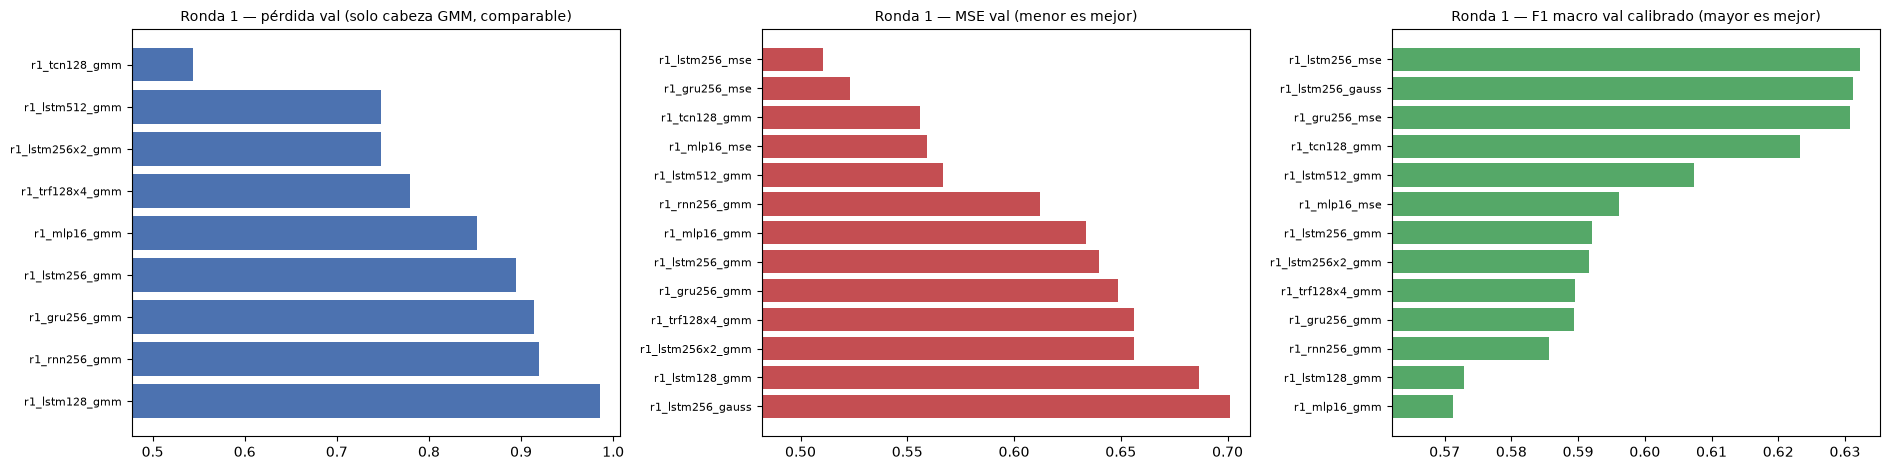

In [12]:
def bar(ax, df, col, title, color):
    df = df.sort_values(col, ascending=col != "val F1 macro (umbral)")
    ax.barh(df["corrida"], df[col], color=color)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
    lo, hi = df[col].min(), df[col].max()
    ax.set_xlim(lo - 0.15 * (hi - lo), hi + 0.05 * (hi - lo))


r1 = experiments[experiments.ronda == "r1"]
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
bar(axes[0], r1[r1["salida (Δx,Δy)"].str.startswith("Mezcla")], "val pérdida",
    "Ronda 1 — pérdida val (solo cabeza GMM, comparable)", "#4c72b0")
bar(axes[1], r1, "val MSE", "Ronda 1 — MSE val (menor es mejor)", "#c44e52")
bar(axes[2], r1, "val F1 macro (umbral)", "Ronda 1 — F1 macro val calibrado (mayor es mejor)", "#55a868")
plt.tight_layout()
plt.show()

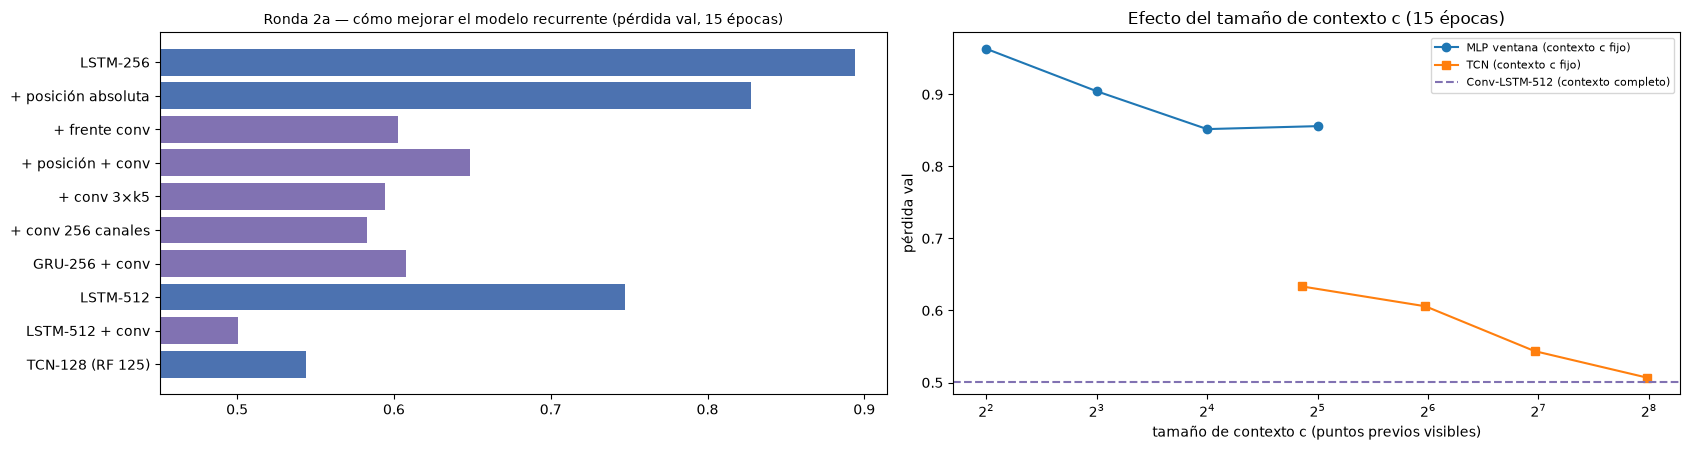

In [13]:
gmm = experiments[experiments["salida (Δx,Δy)"].str.startswith("Mezcla")]
lookup = gmm.set_index("corrida")["val pérdida"]
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6))
pairs = [("LSTM-256", "r1_lstm256_gmm"), ("+ posición absoluta", "r2_lstm256_pos"),
         ("+ frente conv", "r2_lstm256_conv"), ("+ posición + conv", "r2_lstm256_posconv"),
         ("+ conv 3×k5", "r2_lstm256_conv3k5"), ("+ conv 256 canales", "r2_lstm256_conv256"),
         ("GRU-256 + conv", "r2_gru256_conv"), ("LSTM-512", "r1_lstm512_gmm"), ("LSTM-512 + conv", "r2_lstm512_conv"),
         ("TCN-128 (RF 125)", "r1_tcn128_gmm")]
names = [p[0] for p in pairs if p[1] in lookup.index]
vals = [lookup[p[1]] for p in pairs if p[1] in lookup.index]
axes[0].barh(names, vals, color=["#8172b2" if "conv" in n else "#4c72b0" for n in names])
axes[0].invert_yaxis()
axes[0].set_title("Ronda 2a — cómo mejorar el modelo recurrente (pérdida val, 15 épocas)", fontsize=10)
axes[0].set_xlim(min(vals) - 0.05, max(vals) + 0.02)
# tamaño de contexto: MLP de ventana fija y TCN (campo receptivo) frente al Conv-LSTM (contexto completo)
ctx = []
for name, c in [("r2_mlp4_gmm", 4), ("r2_mlp8_gmm", 8), ("r1_mlp16_gmm", 16), ("r2_mlp32_gmm", 32)]:
    if name in lookup.index:
        ctx.append(("MLP ventana", c, lookup[name]))
for name, c in [("r2_tcn128_l3", 29), ("r2_tcn128_k2", 63), ("r1_tcn128_gmm", 125), ("r2_tcn128_l6", 253)]:
    if name in lookup.index:
        ctx.append(("TCN", c, lookup[name]))
ctx = pd.DataFrame(ctx, columns=["modelo", "c", "val pérdida"])
for m, mk in [("MLP ventana", "o-"), ("TCN", "s-")]:
    d = ctx[ctx.modelo == m]
    axes[1].plot(d.c, d["val pérdida"], mk, label=f"{m} (contexto c fijo)")
if "r2_lstm512_conv" in lookup.index:
    axes[1].axhline(lookup["r2_lstm512_conv"], color="#8172b2", ls="--", label="Conv-LSTM-512 (contexto completo)")
axes[1].set_xscale("log", base=2)
axes[1].set(xlabel="tamaño de contexto c (puntos previos visibles)", ylabel="pérdida val",
            title="Efecto del tamaño de contexto c (15 épocas)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [14]:
base = experiments.set_index("corrida").loc["r2_lstm256_conv"]
r2b = experiments[experiments.corrida.str.startswith("r2_clstm256_")].copy()
r2b["Δ pérdida"] = r2b["val pérdida"] - base["val pérdida"]
r2b["Δ MSE"] = r2b["val MSE"] - base["val MSE"]
r2b["Δ F1 argmax"] = r2b["val F1 macro"] - base["val F1 macro"]
r2b["Δ F1 umbral"] = r2b["val F1 macro (umbral)"] - base["val F1 macro (umbral)"]
print(f"Ronda 2b — cambios respecto a la base Conv-LSTM-256 (pérdida {base['val pérdida']:.4f}, "
      f"MSE {base['val MSE']:.4f}, F1 {base['val F1 macro']:.4f}, F1 umbral {base['val F1 macro (umbral)']:.4f}). "
      "Nota: con pesos de clase, w_pen o MSE auxiliar la pérdida cambia de definición.")
display(r2b[["corrida", "cambio", "Δ pérdida", "Δ MSE", "Δ F1 argmax", "Δ F1 umbral", "gen puntos", "gen trazos"]]
        .round(4).reset_index(drop=True))

Ronda 2b — cambios respecto a la base Conv-LSTM-256 (pérdida 0.6026, MSE 0.5779, F1 0.3328, F1 umbral 0.6093). Nota: con pesos de clase, w_pen o MSE auxiliar la pérdida cambia de definición.


,corrida,cambio,Δ pérdida,Δ MSE,Δ F1 argmax,Δ F1 umbral,gen puntos,gen trazos
0,r2_clstm256_bs64,lote = 64,-0.1080,-0.0422,0.0544,0.0137,37.5,3.08
1,r2_clstm256_combo,MSE aux. 1 + w_pen 3 + pesos √,1.3909,-0.0793,0.3036,0.0354,24.1,2.73
2,r2_clstm256_cw_inv,pesos de clase ∝ 1/frecuencia en la CE,0.1603,0.0049,0.2085,0.0129,8.9,1.28
3,r2_clstm256_cw_sqrt,pesos de clase ∝ 1/√frecuencia en la CE,0.1801,-0.0074,0.2769,0.0115,19.7,1.82
4,r2_clstm256_lr2e3,lr = 2e-3,-0.1636,-0.0589,0.1079,0.0248,37.6,3.15
5,r2_clstm256_mix10,M = 10 componentes,0.0577,0.0247,-0.0187,-0.0059,37.0,3.10
6,r2_clstm256_mseaux1,+ 1·MSE de la media de la mezcla,0.4735,-0.0779,0.0251,0.0057,34.0,2.95
7,r2_clstm256_wpen3,w_pen = 3,0.5396,0.0044,0.0357,0.0143,37.9,2.98


#### Ronda 3: candidatos finales con entrenamiento largo

Se entrenó Conv-LSTM-512 con la pérdida combinada, hasta 60 épocas, con `ReduceLROnPlateau` y early stopping con
paciencia 8, igual que en este notebook. Como esta pérdida incluye los pesos `w_mse` y `w_pen`, su escala no se puede
comparar con la de las rondas anteriores.

| Candidato | Épocas (mejor) | Pérdida train | Pérdida val | Diferencia val − train | MSE val | F1 macro val | Bocetos generados (puntos / trazos) |
|---|---|---:|---:|---:|---:|---:|---|
| Conv-LSTM-512, dropout 0.1 | 33 (25) | 1.481 | 1.613 | 0.132 | 0.450 | 0.662 | 33.4 / 2.92 |
| Conv-LSTM-512, dropout 0.3 | 60 (60) | 1.366 | 1.507 | 0.141 | 0.445 | 0.667 | 35.6 / 3.08 |
| Conv-LSTM-512, dropout 0.1 + aumento ±15 % | 42 (34) | 1.245 | 1.560 | 0.316 | 0.450 | 0.665 | 37.9 / 3.52 |
| Conv-LSTM-512, dropout 0.1, lr = 0.001 | 60 (56) | 1.241 | 1.503 | 0.262 | 0.445 | 0.670 | 38.7 / 3.51 |
| TCN-128 (referencia), dropout 0.1 | 60 (60) | 1.589 | 1.758 | 0.169 | 0.482 | 0.647 | 36.3 / 2.98 |

#### Resumen de la búsqueda

1. Ronda 1. La cabeza MSE obtuvo el mejor MSE de validación (0.510 con LSTM-256), pero al generar todos los bocetos
   colapsan a la misma forma promedio. Una sola Gaussiana tampoco fue suficiente (MSE 0.701). La mezcla de Gaussianas
   fue la única que produjo bocetos variados. Entre los modelos recurrentes con GMM, la LSTM superó a la RNN simple y a
   la GRU, y el tamaño importó bastante (pérdida de 0.985 con LSTM-128, 0.894 con LSTM-256 y 0.748 con LSTM-512). El
   Transformer causal (0.780) no superó a la LSTM-512 y fue el más lento. La mejor fue la TCN causal (0.544), lo que
   sugería que ver directamente los puntos previos ayudaba más que lo que la LSTM alcanzaba a recordar en su estado.
2. Ronda 2a. Agregar la posición absoluta del lápiz ayudó poco (de 0.894 a 0.828) y empeoró al combinarla con
   convoluciones. En cambio, agregar un frente convolucional causal antes de la LSTM mejoró mucho: de 0.894 a 0.603
   con LSTM-256 y de 0.748 a 0.501 con LSTM-512, mejor que la TCN. Usar más canales (256) o un kernel más ancho (3
   capas con k = 5) solo dio mejoras pequeñas, y la GRU con frente convolucional quedó un poco por debajo de la LSTM.
3. Ronda 2c. Con contexto fijo, ver más puntos siempre ayudó. Con el MLP, c = 4 dio 0.963, c = 8 dio 0.904 y c = 16
   dio 0.852 (con c = 32, 0.856, ya no mejora); con la TCN, un campo receptivo de 29 dio 0.633, de 63 dio 0.606, de 125
   dio 0.544 y de 253 dio 0.507. El Conv-LSTM aprovecha las dos cosas: contexto local preciso por las convoluciones y
   contexto completo por la LSTM, sin tener que fijar `c`.
4. Ronda 2b. Los pesos de clase ∝ 1/√frecuencia subieron el F1 macro con argmax de 0.333 a 0.610; con pesos
   ∝ 1/frecuencia el F1 fue 0.541, porque la ponderación resultó demasiado fuerte. El término MSE bajó el MSE de 0.578
   a 0.500 y mejoró la NLL, y `w_pen = 3` mejoró la separabilidad de los estados del lápiz. Combinar los tres fue lo
   mejor en todas las métricas (MSE 0.499, F1 0.636, F1 calibrado 0.645). Con M = 10 componentes los resultados
   empeoraron, así que se mantuvo M = 20. La tasa de aprendizaje de 0.002 fue el cambio de entrenamiento más útil (la
   NLL bajó de 0.331 a 0.181). Un lote de 64 también ayudó (NLL de 0.231), sobre todo porque hace el doble de
   actualizaciones por época; se prefirió subir la tasa de aprendizaje y mantener el lote de 128.
5. Ronda 3. Con 33 a 60 épocas aparecieron diferencias que no se veían en las rondas cortas. Con dropout 0.1 el
   modelo empezó a sobreajustar: la pérdida de entrenamiento siguió bajando mientras la de validación se estancó, y el
   early stopping lo detuvo en la época 33 (mejor época 25, pérdida de validación 1.613). El aumento de datos retrasó
   el problema, pero terminó con la mayor diferencia entre validación y entrenamiento (0.316, con pérdida de validación
   1.560). Dropout 0.3 (1.507) y la tasa de 0.001 (1.503) quedaron prácticamente empatados; la diferencia es menor a
   0.005, del orden de la variación entre semillas. Se eligió dropout 0.3 porque su diferencia entre validación y
   entrenamiento es casi la mitad (0.141 frente a 0.262) y porque sus bocetos tienen un número de trazos más parecido
   al de los reales (3.08 frente a 3.51; los reales tienen 3.17). Con el mismo entrenamiento largo, la TCN quedó
   claramente por debajo (1.758).

Configuración final: frente convolucional de 2 capas `Conv1d` (kernel 3, 128 canales), LSTM de 512 unidades y dropout
de 0.3; mezcla de 20 Gaussianas; pérdida `NLL + 1·MSE + 3·CE ponderada` con pesos ∝ 1/√frecuencia; Adam con tasa de
aprendizaje de 0.002, lotes de 128, `ReduceLROnPlateau` y early stopping sobre la pérdida de validación. Esta es la
configuración que se entrena a continuación.

El notebook usa el mismo modelo, la misma pérdida y los mismos hiperparámetros que la corrida de la ronda 3, pero con
su propio `DataLoader`, que reparte los lotes en otro orden aleatorio. Por eso el entrenamiento no es idéntico: aquí la
mejor pérdida de validación es 1.538 (época 48), frente a 1.507 en la ronda 3, una diferencia del orden de la
variación entre semillas.

### 7.3 Bucle de entrenamiento

- Optimizador Adam con tasa de aprendizaje de 0.002, lotes de 128 bocetos agrupados por longitud y recorte de
  gradientes con norma máxima 1.0 para estabilizar el entrenamiento de la LSTM.
- La tasa de aprendizaje se reduce a la mitad cuando la pérdida de validación no mejora durante 3 épocas
  (`ReduceLROnPlateau`).
- Early stopping sobre la pérdida de validación: se guarda el mejor estado y el entrenamiento se detiene tras 8 épocas
  sin mejora, con un máximo de 60 épocas. Validación y prueba usan exactamente la misma pérdida y la misma máscara que
  el entrenamiento.
- En cada época se registran las pérdidas de entrenamiento y validación con sus componentes, además del MSE y el F1
  macro de validación.

El entrenamiento tarda alrededor de 40 minutos en CPU (portátil con procesador i7 de 12.ª generación) y unos pocos
minutos con GPU.

La celda siguiente tiene el interruptor `ENTRENAR`. Con `ENTRENAR = True` (valor por defecto) el modelo se entrena desde
cero. Con `ENTRENAR = False` se omite el entrenamiento y se carga el modelo final ya entrenado: primero se busca el
archivo `modelo_convlstm_fish.pt` en la carpeta del notebook y, si no está, se descarga del repositorio del equipo. El
archivo guarda también el historial de entrenamiento, así que las curvas de la sección 7.4 se dibujan en ambos casos,
y como el modelo es el mismo, las métricas y los bocetos de las secciones 8 y 9 dan los mismos resultados.

In [15]:
def run_epoch(model, loader, optimizer):
    """Una época de entrenamiento. Devuelve las pérdidas promedio por punto [total, NLL, MSE, pen]."""
    model.train()
    sums, n_total = np.zeros(4), 0.0
    for X, Y, L in loader:
        X, Y, L = X.to(DEVICE), Y.to(DEVICE), L.to(DEVICE)
        if HP["augment"] > 0:      # aumento de datos: escalado aleatorio de (Δx, Δy) por boceto (solo en train)
            f = 1 + (torch.rand(X.size(0), 1, 2, device=DEVICE) * 2 - 1) * HP["augment"]
            X, Y = X.clone(), Y.clone()
            X[..., 0:2] *= f
            Y[..., 0:2] *= f
        raw_gmm, pen_logits, _ = model(X)
        loss, parts, n = compute_loss(raw_gmm, pen_logits, Y, L)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), HP["clip"])
        optimizer.step()
        sums += np.concatenate([[loss.item()], parts.detach().cpu().numpy()]) * n.item()
        n_total += n.item()
    return sums / n_total


@torch.no_grad()
def predict(model, loader):
    """Predicción a un paso (los puntos reales anteriores son el contexto) sobre todos los puntos reales.

    Devuelve las predicciones y objetivos de TODOS los puntos reales juntos (agregación por punto) y la
    pérdida promedio por punto con sus componentes.
    """
    model.eval()
    out = {"mean": [], "target": [], "logits": [], "cls": []}
    sums, n_total = np.zeros(4), 0.0
    for X, Y, L in loader:
        X, Y, L = X.to(DEVICE), Y.to(DEVICE), L.to(DEVICE)
        raw_gmm, pen_logits, _ = model(X)
        loss, parts, n = compute_loss(raw_gmm, pen_logits, Y, L)
        sums += np.concatenate([[loss.item()], parts.cpu().numpy()]) * n.item()
        n_total += n.item()
        mask = make_mask(L, Y.size(1))                       # descarta el relleno
        out["mean"].append(gmm_mean(gmm_params(raw_gmm, model.n_mix))[mask].cpu())
        out["target"].append(Y[..., 0:2][mask].cpu())
        out["logits"].append(pen_logits[mask].cpu())
        out["cls"].append(Y[..., 2:].argmax(-1)[mask].cpu())
    out = {k: torch.cat(v).numpy() for k, v in out.items()}
    out["loss"], out["loss_nll"], out["loss_mse"], out["loss_pen"] = sums / n_total
    return out


def compute_metrics(pred, bias=None):
    """MSE (Δx, Δy) y F1 macro (pen_state) sobre la lista global de puntos reales, más la pérdida."""
    logits = pred["logits"] if bias is None else pred["logits"] + bias
    y_hat = logits.argmax(1)
    return {"loss": pred["loss"], "loss_nll": pred["loss_nll"], "loss_mse": pred["loss_mse"],
            "loss_pen": pred["loss_pen"],
            "mse_norm": mean_squared_error(pred["target"], pred["mean"]),
            "mse_px": mean_squared_error(pred["target"] * SCALE, pred["mean"] * SCALE),
            "f1_macro": f1_score(pred["cls"], y_hat, average="macro"),
            "n_points": len(y_hat)}


def train_model(model, hp=HP, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5,
                                                           patience=hp["lr_patience"])
    train_loader = make_loader(X_train, Y_train, L_train, hp["batch_size"], shuffle=True)
    valid_loader = make_loader(X_valid, Y_valid, L_valid, 500, shuffle=False)
    history, best_loss, best_state, best_epoch, wait = [], float("inf"), None, 0, 0
    for epoch in range(1, hp["epochs"] + 1):
        t0 = time.time()
        tr = run_epoch(model, train_loader, optimizer)
        val = compute_metrics(predict(model, valid_loader))
        lr = optimizer.param_groups[0]["lr"]
        scheduler.step(val["loss"])
        history.append({"epoch": epoch, "train_loss": tr[0], "train_nll": tr[1], "train_mse": tr[2],
                        "train_pen": tr[3], "val_loss": val["loss"], "val_nll": val["loss_nll"],
                        "val_mse": val["mse_norm"], "val_pen": val["loss_pen"], "val_f1": val["f1_macro"],
                        "lr": lr})
        improved = val["loss"] < best_loss - 1e-4
        if improved:
            best_loss, best_state, best_epoch, wait = val["loss"], copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
        if verbose:
            print(f"época {epoch:3d} | train {tr[0]:.4f} | val {val['loss']:.4f} | MSE val {val['mse_norm']:.4f} | "
                  f"F1 val {val['f1_macro']:.4f} | lr {lr:.1e} | {time.time() - t0:4.1f}s {'*' if improved else ''}")
        if wait >= hp["patience"]:
            print(f"Early stopping: {hp['patience']} épocas sin mejorar (mejor época: {best_epoch}).")
            break
    model.load_state_dict(best_state)
    return pd.DataFrame(history), best_epoch


In [16]:
# True: entrena el modelo desde cero (alrededor de 40 min en CPU, unos minutos con GPU).
# False: carga el modelo final ya entrenado (archivo local o descarga desde el repositorio del equipo).
ENTRENAR = True

PESOS = f"modelo_convlstm_{CATEGORY}.pt"
URLS_PESOS = [f"https://raw.githubusercontent.com/jcrkboy/mp1_equipo_21/{ref}/aportes/juan_rodriguez/sketchrnn_fish/{PESOS}"
              for ref in ("601e970bb8619083138010b071a1c624ecc29941", "main", "aporte/juan-rodriguez-fish")]
ARQUITECTURA = ["conv_channels", "conv_layers", "kernel_size", "hidden_size", "num_layers", "n_mix"]

set_seed()
model = SketchConvLSTM().to(DEVICE)
if ENTRENAR:
    t_start = time.time()
    history, best_epoch = train_model(model)
    print(f"Tiempo total de entrenamiento: {(time.time() - t_start) / 60:.1f} min | mejor época: {best_epoch}")
    torch.save({"state_dict": model.state_dict(), "HP": HP, "scale": [float(s) for s in SCALE],
                "history": {k: [float(v) for v in history[k]] for k in history.columns},
                "best_epoch": int(best_epoch)}, PESOS)
    print(f"Modelo guardado en {PESOS}")
else:
    if not os.path.exists(PESOS):
        for url in URLS_PESOS:
            try:
                urllib.request.urlretrieve(url, PESOS)
                print("Modelo descargado de", url)
                break
            except Exception as error:
                print("No se pudo descargar de", url, "->", error)
    checkpoint = torch.load(PESOS, map_location=DEVICE, weights_only=True)
    assert all(checkpoint["HP"][k] == HP[k] for k in ARQUITECTURA), "la arquitectura del archivo no coincide con HP"
    assert np.allclose(checkpoint["scale"], SCALE, atol=1e-4), "la escala de normalización no coincide"
    model.load_state_dict(checkpoint["state_dict"])
    history, best_epoch = pd.DataFrame(checkpoint["history"]), checkpoint["best_epoch"]
    print(f"Modelo cargado de {PESOS} | mejor época del entrenamiento original: {best_epoch}")

época   1 | train 4.0636 | val 2.8813 | MSE val 0.6320 | F1 val 0.5674 | lr 2.0e-03 | 40.7s *


época   2 | train 2.7532 | val 2.5721 | MSE val 0.5608 | F1 val 0.5938 | lr 2.0e-03 | 45.1s *


época   3 | train 2.5173 | val 2.3064 | MSE val 0.5246 | F1 val 0.6154 | lr 2.0e-03 | 48.4s *


época   4 | train 2.3361 | val 2.2723 | MSE val 0.5259 | F1 val 0.6102 | lr 2.0e-03 | 45.4s *


época   5 | train 2.2841 | val 2.4151 | MSE val 0.5372 | F1 val 0.6035 | lr 2.0e-03 | 44.7s 


...

época  53 | train 1.2710 | val 1.5425 | MSE val 0.4488 | F1 val 0.6697 | lr 6.3e-05 | 41.9s 


época  54 | train 1.2647 | val 1.5506 | MSE val 0.4507 | F1 val 0.6683 | lr 6.3e-05 | 40.7s 


época  55 | train 1.2635 | val 1.5523 | MSE val 0.4500 | F1 val 0.6707 | lr 6.3e-05 | 42.1s 


época  56 | train 1.2597 | val 1.5541 | MSE val 0.4506 | F1 val 0.6710 | lr 6.3e-05 | 42.0s 
Early stopping: 8 épocas sin mejorar (mejor época: 48).
Tiempo total de entrenamiento: 41.4 min | mejor época: 48


Modelo guardado en modelo_convlstm_fish.pt


### 7.4 Curvas de entrenamiento y validación

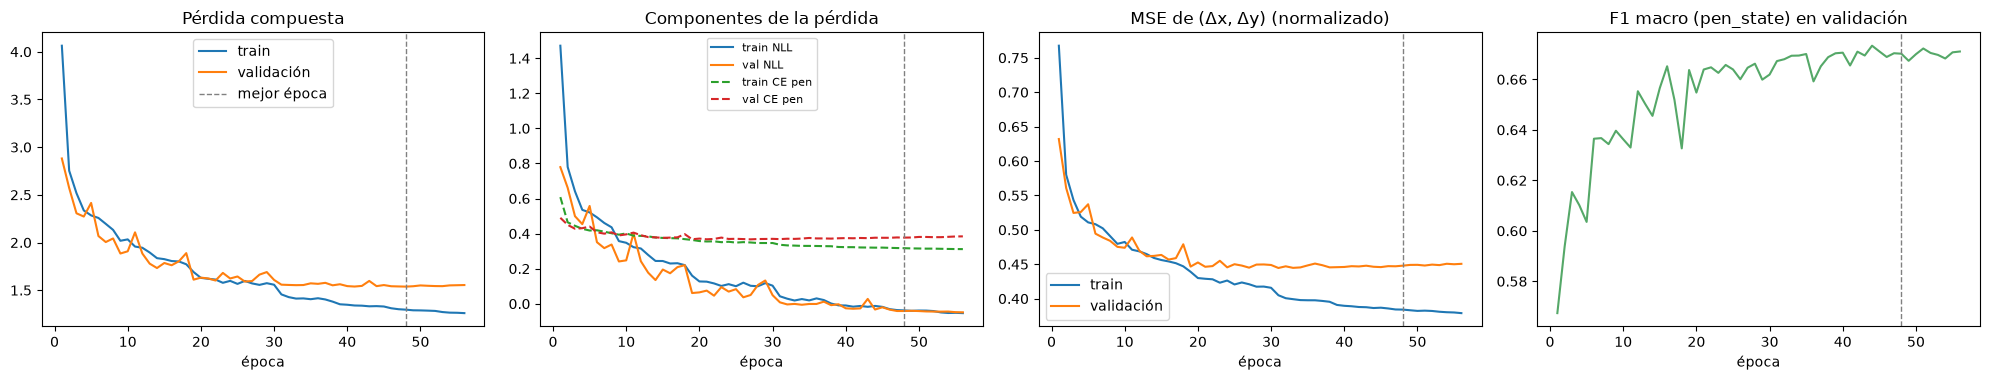

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.9))
h = history
axes[0].plot(h.epoch, h.train_loss, label="train")
axes[0].plot(h.epoch, h.val_loss, label="validación")
axes[0].axvline(best_epoch, ls="--", c="gray", lw=1, label="mejor época")
axes[0].set(title="Pérdida compuesta", xlabel="época")
axes[0].legend()
axes[1].plot(h.epoch, h.train_nll, label="train NLL")
axes[1].plot(h.epoch, h.val_nll, label="val NLL")
axes[1].plot(h.epoch, h.train_pen, "--", label="train CE pen")
axes[1].plot(h.epoch, h.val_pen, "--", label="val CE pen")
axes[1].axvline(best_epoch, ls="--", c="gray", lw=1)
axes[1].set(title="Componentes de la pérdida", xlabel="época")
axes[1].legend(fontsize=8)
axes[2].plot(h.epoch, h.train_mse, label="train")
axes[2].plot(h.epoch, h.val_mse, label="validación")
axes[2].axvline(best_epoch, ls="--", c="gray", lw=1)
axes[2].set(title="MSE de (Δx, Δy) (normalizado)", xlabel="época")
axes[2].legend()
axes[3].plot(h.epoch, h.val_f1, c="#55a868")
axes[3].axvline(best_epoch, ls="--", c="gray", lw=1)
axes[3].set(title="F1 macro (pen_state) en validación", xlabel="época")
plt.tight_layout()
plt.show()

## 8. Evaluación del modelo

Las métricas se calculan con predicción a un paso: para cada punto se usan como contexto los puntos reales anteriores.
Se juntan todos los puntos reales de los 2.000 bocetos de prueba en una sola lista, descartando el relleno con la
máscara, y sobre esa lista se calcula una única métrica global:

- MSE de `(Δx, Δy)`: error cuadrático medio entre la predicción puntual del modelo (la media de la mezcla,
  $\sum_k \pi_k \mu_k$) y el valor real, promediado sobre los puntos y las dos coordenadas. Se reporta en unidades
  normalizadas, que son las que usa el modelo, y en píxeles².
- F1 macro de `pen_state` (3 clases), tomando la clase más probable.
- Pérdida compuesta, con la misma fórmula, los mismos pesos y la misma máscara del entrenamiento, junto con sus
  componentes.

Como referencia también se reportan entrenamiento y validación, para analizar el sobreajuste, y un modelo trivial que
siempre predice Δ = 0 y "lápiz abajo".

In [18]:
eval_loaders = {name: make_loader(X, Y, L, 500, shuffle=False)
                for name, (X, Y, L) in {"train": (X_train, Y_train, L_train), "validación": (X_valid, Y_valid, L_valid),
                                        "prueba": (X_test, Y_test, L_test)}.items()}
preds = {name: predict(model, loader) for name, loader in eval_loaders.items()}
results = pd.DataFrame({name: compute_metrics(p) for name, p in preds.items()}).T
pt = preds["prueba"]
baseline = {"loss": np.nan, "loss_nll": np.nan, "loss_mse": np.nan, "loss_pen": np.nan,
            "mse_norm": mean_squared_error(pt["target"], np.zeros_like(pt["target"])),
            "mse_px": mean_squared_error(pt["target"] * SCALE, np.zeros_like(pt["target"])),
            "f1_macro": f1_score(pt["cls"], np.zeros_like(pt["cls"]), average="macro"), "n_points": len(pt["cls"])}
results.loc["prueba: modelo trivial"] = baseline
results["n_points"] = results["n_points"].astype(int)
display(results.round(4))

test_metrics = compute_metrics(pt)
print("=" * 72)
print(f"CONJUNTO DE PRUEBA ({test_metrics['n_points']:,} puntos reales de {N_TEST:,} bocetos)")
print(f"  Pérdida compuesta : {test_metrics['loss']:.4f}  = NLL {test_metrics['loss_nll']:.4f} + "
      f"{HP['w_mse']:g}·MSE {test_metrics['loss_mse']:.4f} + {HP['w_pen']:g}·CE pen {test_metrics['loss_pen']:.4f}")
print(f"  MSE (Δx, Δy)      : {test_metrics['mse_norm']:.4f} (normalizado) | {test_metrics['mse_px']:.2f} px²")
print(f"  F1 macro pen_state: {test_metrics['f1_macro']:.4f}")
print("=" * 72)

,loss,loss_nll,loss_mse,loss_pen,mse_norm,mse_px,f1_macro,n_points
train,1.1460,-0.1463,0.3699,0.3075,0.3697,690.4595,0.7127,610432
validación,1.5377,-0.0417,0.4480,0.3771,0.4480,857.1643,0.6702,75896
prueba,1.5250,-0.0522,0.4560,0.3737,0.4560,882.4550,0.6702,76135
prueba: modelo trivial,NaN,NaN,NaN,NaN,0.9934,1960.2947,0.3142,76135


CONJUNTO DE PRUEBA (76,135 puntos reales de 2,000 bocetos)
  Pérdida compuesta : 1.5250  = NLL -0.0522 + 1·MSE 0.4560 + 3·CE pen 0.3737
  MSE (Δx, Δy)      : 0.4560 (normalizado) | 882.46 px²
  F1 macro pen_state: 0.6702


Umbrales de decisión calibrados en validación. Con clases tan desbalanceadas, tomar siempre la clase más probable
tiende a favorecer "lápiz abajo". Como alternativa, se ajusta en validación un sesgo para los logits de las clases
minoritarias (equivale a mover los umbrales de decisión), eligiendo el que maximiza el F1 macro de validación, y luego
se aplica sin cambios a prueba. Solo cambia la regla de decisión, no el modelo. Como el modelo ya se entrenó con pesos
de clase, esperamos que el sesgo óptimo sea pequeño y que la mejora sea poca; si es así, el argmax ya está cerca del
mejor umbral.

In [19]:
def fast_f1_macro(y_true, y_pred, k=3):
    cm = np.bincount(y_true * k + y_pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float)
    prec = np.divide(tp, cm.sum(0), out=np.zeros(k), where=cm.sum(0) > 0)
    rec = np.divide(tp, cm.sum(1), out=np.zeros(k), where=cm.sum(1) > 0)
    return np.mean(np.divide(2 * prec * rec, prec + rec, out=np.zeros(k), where=(prec + rec) > 0))


grid = np.linspace(-4, 4, 33)
pv = preds["validación"]
best_bias = np.zeros(3, dtype=np.float32)                      # punto de partida: argmax (sin sesgo)
best_f1 = fast_f1_macro(pv["cls"], pv["logits"].argmax(1))
for b1 in grid:
    for b2 in grid:
        b = np.array([0.0, b1, b2], dtype=np.float32)
        f1v = fast_f1_macro(pv["cls"], (pv["logits"] + b).argmax(1))
        if f1v > best_f1:
            best_f1, best_bias = f1v, b
f1_cal = {name: f1_score(p["cls"], (p["logits"] + best_bias).argmax(1), average="macro") for name, p in preds.items()}
print(f"Sesgos calibrados en validación: fin de trazo {best_bias[1]:+.2f}, fin de dibujo {best_bias[2]:+.2f}")
display(pd.DataFrame({"F1 macro (argmax)": results.loc[list(preds), "f1_macro"].astype(float),
                      "F1 macro (umbrales calibrados en validación)": pd.Series(f1_cal)}).round(4))
test_metrics["f1_macro_calibrado"] = f1_cal["prueba"]
print(f"F1 macro en prueba: {test_metrics['f1_macro']:.4f} (argmax) | {f1_cal['prueba']:.4f} (umbrales calibrados)")

Sesgos calibrados en validación: fin de trazo -0.25, fin de dibujo -1.00


,F1 macro (argmax),F1 macro (umbrales calibrados en validación)
train,0.7127,0.7325
validación,0.6702,0.6773
prueba,0.6702,0.6781


F1 macro en prueba: 0.6702 (argmax) | 0.6781 (umbrales calibrados)


Ahora revisamos el detalle por clase y por coordenada en prueba.

Clasificación de pen_state en prueba — argmax
               precision    recall  f1-score   support

  lápiz abajo     0.9603    0.8844    0.9208     67855
 fin de trazo     0.4114    0.6188    0.4942      6280
fin de dibujo     0.4396    0.9235    0.5956      2000

     accuracy                         0.8635     76135
    macro avg     0.6038    0.8089    0.6702     76135
 weighted avg     0.9014    0.8635    0.8771     76135

Clasificación de pen_state en prueba — umbrales calibrados en validación
               precision    recall  f1-score   support

  lápiz abajo     0.9519    0.9117    0.9314     67855
 fin de trazo     0.4432    0.5624    0.4957      6280
fin de dibujo     0.4945    0.7865    0.6072      2000

     accuracy                         0.8796     76135
    macro avg     0.6299    0.7535    0.6781     76135
 weighted avg     0.8980    0.8796    0.8869     76135

MSE por coordenada (px²): Δx = 1169.70 | Δy = 595.26


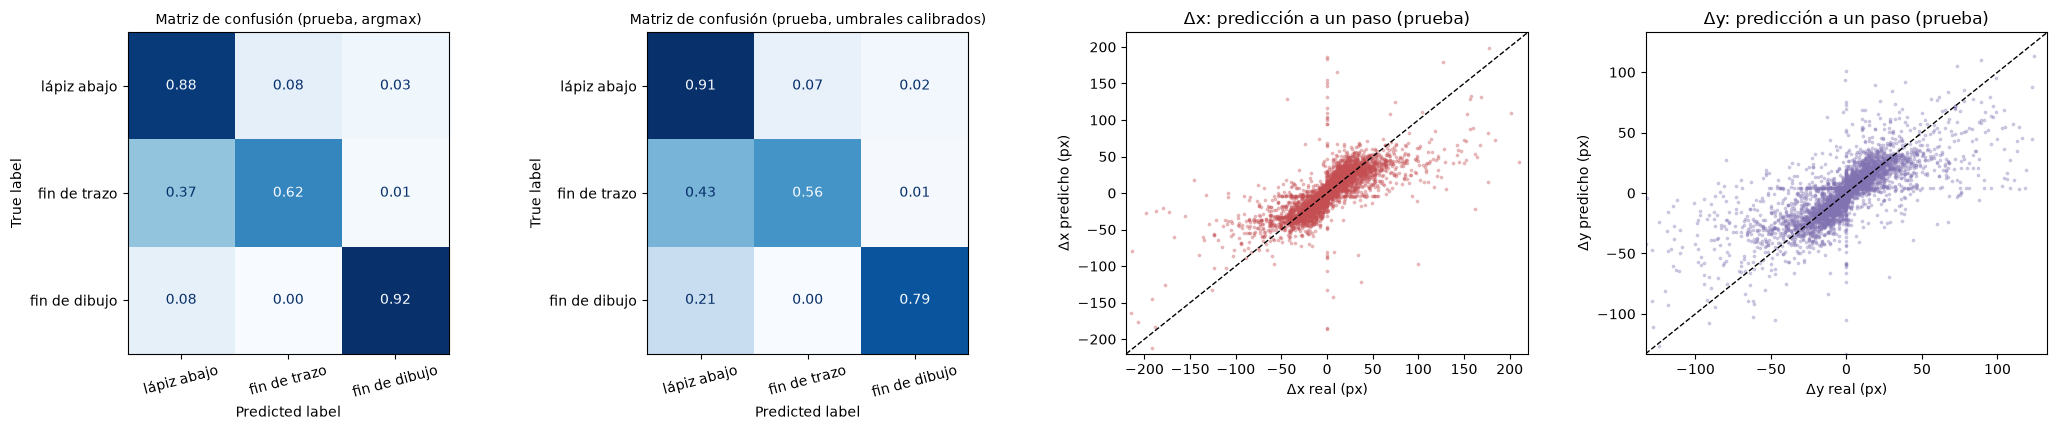

In [20]:
y_true, y_pred = pt["cls"], pt["logits"].argmax(1)
y_pred_cal = (pt["logits"] + best_bias).argmax(1)
print("Clasificación de pen_state en prueba — argmax")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
print("Clasificación de pen_state en prueba — umbrales calibrados en validación")
print(classification_report(y_true, y_pred_cal, target_names=CLASS_NAMES, digits=4, zero_division=0))
err_px = (pt["mean"] - pt["target"]) * SCALE
print(f"MSE por coordenada (px²): Δx = {np.mean(err_px[:, 0] ** 2):.2f} | Δy = {np.mean(err_px[:, 1] ** 2):.2f}")

fig, axes = plt.subplots(1, 4, figsize=(21, 4.4))
for ax, yp, title in [(axes[0], y_pred, "argmax"), (axes[1], y_pred_cal, "umbrales calibrados")]:
    ConfusionMatrixDisplay(confusion_matrix(y_true, yp, normalize="true"), display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"Matriz de confusión (prueba, {title})", fontsize=10)
    ax.tick_params(axis="x", labelrotation=15)
for j, (name, c) in enumerate([("Δx", "#c44e52"), ("Δy", "#8172b2")]):
    idx = np.random.default_rng(0).choice(len(pt["target"]), 4000, replace=False)
    axes[j + 2].scatter(pt["target"][idx, j] * SCALE[j], pt["mean"][idx, j] * SCALE[j], s=3, alpha=0.3, c=c)
    lim = np.percentile(np.abs(pt["target"][:, j] * SCALE[j]), 99)
    axes[j + 2].plot([-lim, lim], [-lim, lim], "k--", lw=1)
    axes[j + 2].set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel=f"{name} real (px)", ylabel=f"{name} predicho (px)",
                    title=f"{name}: predicción a un paso (prueba)")
plt.tight_layout()
plt.show()

## 9. Generación de ejemplos

La generación es autorregresiva. Se parte del punto inicial `S0 = (0, 0, 1, 0, 0)` y, en cada paso, el modelo recibe
el punto anterior junto con su estado recurrente `(h, c)`, que resume todos los puntos previos:

1. La cabeza de regresión entrega la mezcla de Gaussianas y de ella se muestrea `(Δx, Δy)`. La temperatura `τ`
   controla la aleatoriedad: afila los pesos `π` (softmax de `log π / τ`) y multiplica las varianzas por `τ`. Con `τ`
   cerca de 0 se toma prácticamente la componente más probable; con `τ = 1` se muestrea la distribución aprendida.
2. Se muestrea el estado del lápiz. Como la entropía cruzada se ponderó con pesos de clase $w_c$, la softmax del
   modelo sobrestima los estados poco frecuentes. Por eso al muestrear se usa $\mathrm{softmax}(z - \log w)$, que
   compensa la ponderación y devuelve probabilidades calibradas (corrección de priors). Sin esta corrección los
   bocetos terminan demasiado pronto.
3. La generación se detiene cuando el modelo predice fin de dibujo o al llegar a 200 puntos.
4. Se revierte la normalización y el boceto se convierte a stroke-3 para dibujarlo.

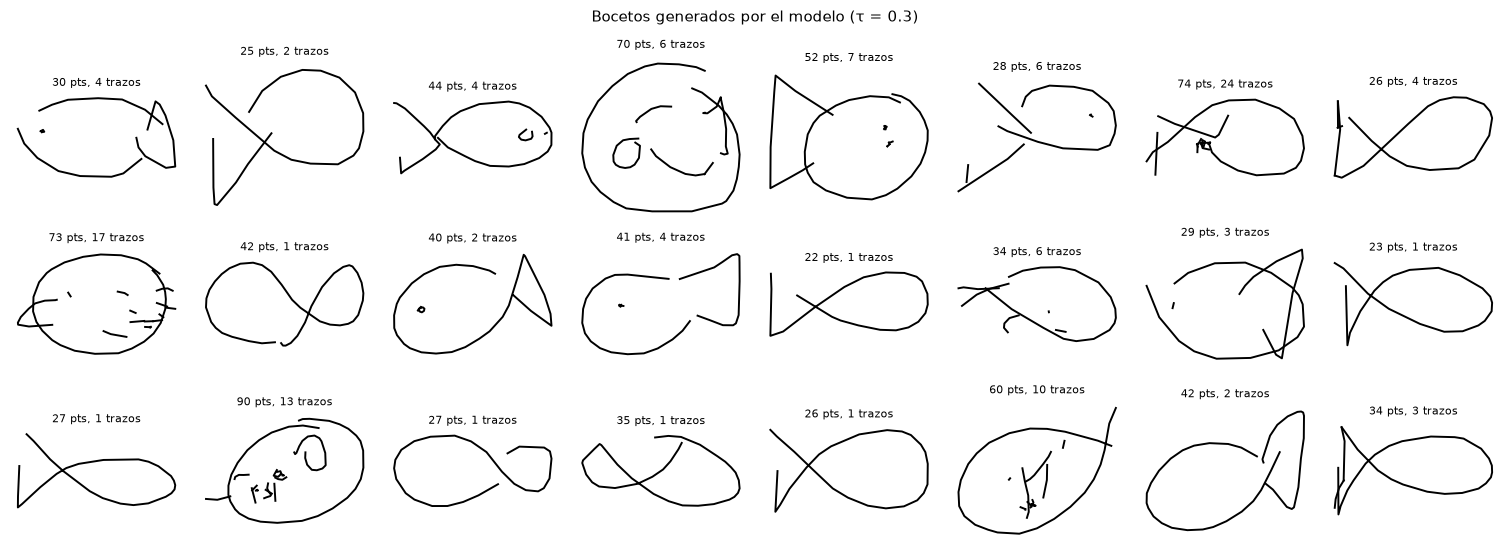

In [21]:
LOG_W = torch.log(CLASS_WEIGHTS)       # corrección de priors al muestrear pen_state


@torch.no_grad()
def generate(model, n=1, temperature=0.4, pen_temperature=1.0, max_points=MAX_POINTS, seed=0, prior_correction=True):
    """Genera n bocetos en paralelo. Devuelve una lista de arreglos stroke-3 en la escala original."""
    model.eval()
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    x = torch.as_tensor(START_TOKEN, device=DEVICE).repeat(n, 1, 1)        # (n, 1, 5): semilla S0
    end = torch.as_tensor(END_TOKEN, device=DEVICE)
    state, done = None, torch.zeros(n, dtype=torch.bool, device=DEVICE)
    lengths = torch.full((n,), max_points, device=DEVICE)
    points = torch.zeros(n, max_points, 5, device=DEVICE)
    for t in range(max_points):
        raw_gmm, pen_logits, state = model(x, state)
        dxdy = gmm_sample(gmm_params(raw_gmm[:, -1], model.n_mix), temperature, g)
        z = pen_logits[:, -1] - (LOG_W if prior_correction else 0.0)
        pen = torch.multinomial(F.softmax(z / pen_temperature, dim=-1), 1, generator=g).squeeze(1)
        if t == max_points - 1:
            pen = torch.full_like(pen, 2)                                     # límite de 200 puntos
        p = torch.zeros(n, 5, device=DEVICE)
        p[:, 0:2] = dxdy
        p[torch.arange(n, device=DEVICE), 2 + pen] = 1.0
        p[pen == 2, 0:2] = 0.0
        p[done] = end                                                          # ya terminados: relleno
        points[:, t] = p
        newly_done = (~done) & (pen == 2)
        lengths[newly_done] = t + 1
        done |= newly_done
        if bool(done.all()):
            break
        x = p.unsqueeze(1)                                                     # el punto vuelve como entrada
    points = points.cpu().numpy()
    return [to_stroke3(denormalize(points[i, :int(lengths[i])], SCALE)) for i in range(n)]


TEMPERATURE = HP["temperature"]
samples = generate(model, n=24, temperature=TEMPERATURE, seed=1)
show_grid(samples, ncols=8, titles=[f"{len(s)} pts, {int(s[:, 2].sum())} trazos" for s in samples],
          suptitle=f"Bocetos generados por el modelo (τ = {TEMPERATURE})")

Efecto de la temperatura: con temperaturas bajas los trazos son más suaves y parecidos entre sí; con temperaturas
altas los bocetos son más variados, pero también más ruidosos.

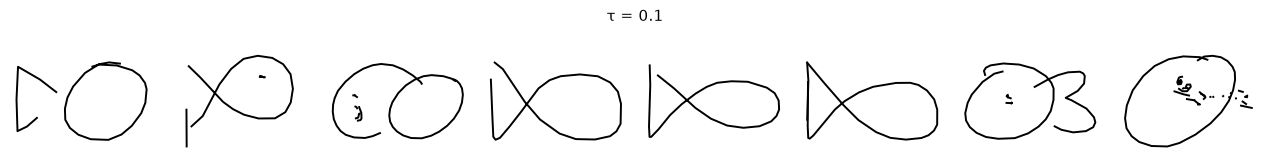

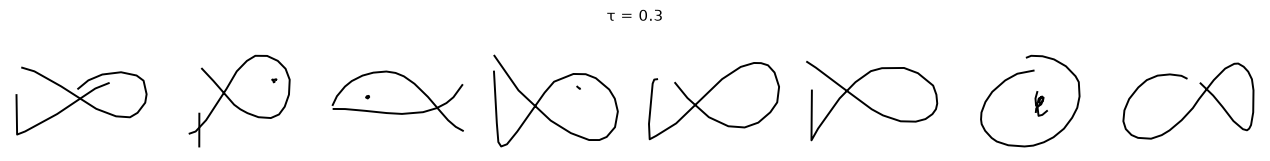

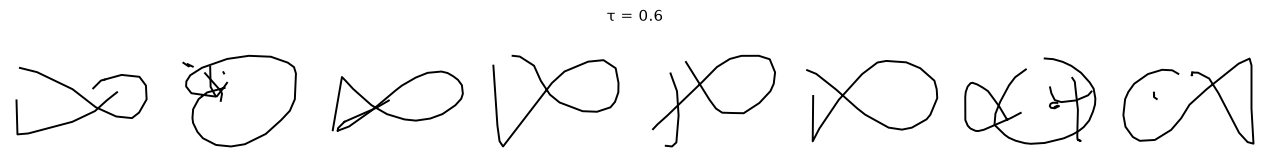

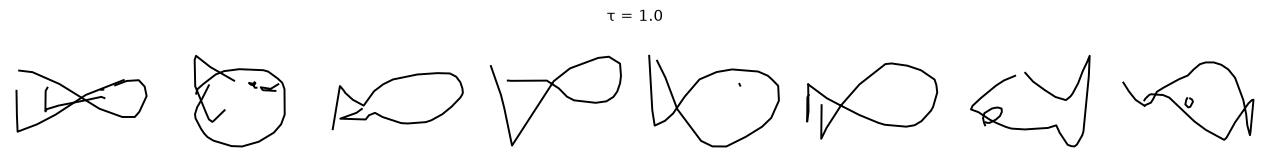

In [22]:
for tau in [0.1, 0.3, 0.6, 1.0]:
    show_grid(generate(model, n=8, temperature=tau, seed=7), ncols=8, size=1.6, suptitle=f"τ = {tau}")

Para comprobar de forma cuantitativa que el modelo aprendió la estructura de la categoría, comparamos el número de
puntos y de trazos de 500 bocetos generados con los 2.000 bocetos de validación, con y sin la corrección de priors.

In [23]:
real = [to_stroke3(s) for s in valid5]
gen = generate(model, n=500, temperature=TEMPERATURE, seed=123)
gen_raw = generate(model, n=500, temperature=TEMPERATURE, seed=123, prior_correction=False)
rows = {"reales (validación)": real, f"generados (τ = {TEMPERATURE}, con corrección de priors)": gen,
        f"generados (τ = {TEMPERATURE}, sin corrección)": gen_raw}
stats = pd.DataFrame({name: {"puntos (media)": np.mean([len(s) for s in sk]),
                             "trazos (media)": np.mean([s[:, 2].sum() for s in sk]),
                             "bocetos con < 10 puntos": np.mean([len(s) < 10 for s in sk])}
                      for name, sk in rows.items()}).T
display(stats.round(3))

,puntos (media),trazos (media),bocetos con < 10 puntos
reales (validación),36.948,3.174,0.000
"generados (τ = 0.3, con corrección de priors)",37.168,3.560,0.002
"generados (τ = 0.3, sin corrección)",30.468,3.608,0.004


Archivos PNG. Se guardan 3 bocetos completos generados por el modelo. Para que representen la salida típica, se
generan 24 bocetos con una semilla fija y se toman los 3 primeros que cumplen tres condiciones: (1) el modelo los
terminó por sí mismo, es decir, predijo fin de dibujo antes de los 200 puntos; (2) su número de puntos está dentro del
rango intercuartílico de los bocetos reales de validación; y (3) no tienen más trazos que el percentil 75 de los
reales. Este filtro solo descarta bocetos degenerados o muy recargados; la grilla anterior muestra muestras sin ningún
filtro.

Criterio: 27 ≤ puntos ≤ 44 y trazos ≤ 4 | candidatos que lo cumplen: 13 de 24
Guardado boceto_generado_1.png: 35 puntos
Guardado boceto_generado_2.png: 40 puntos
Guardado boceto_generado_3.png: 32 puntos


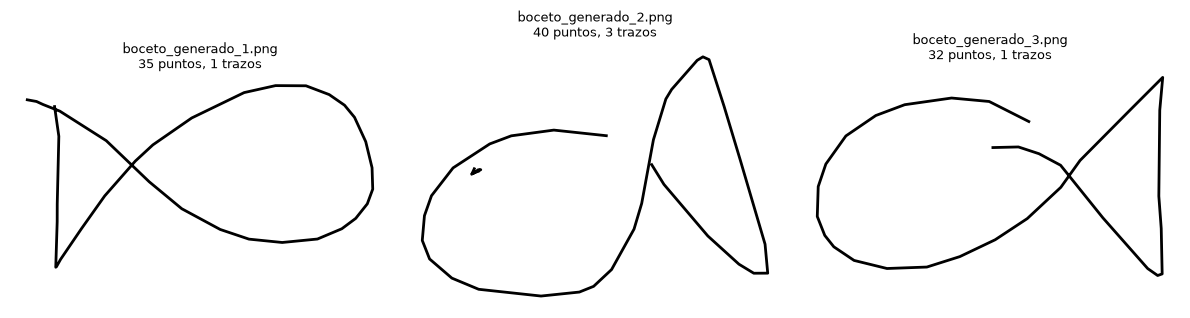

In [24]:
real_len = np.array([len(s) for s in real])
real_strokes = np.array([s[:, 2].sum() for s in real])
q1, q3 = np.percentile(real_len, [25, 75])
max_strokes = np.percentile(real_strokes, 75)
candidates = generate(model, n=24, temperature=TEMPERATURE, seed=HP["png_seed"])
final_samples = [s for s in candidates
                 if len(s) < MAX_POINTS - 1 and q1 <= len(s) <= q3 and s[:, 2].sum() <= max_strokes][:3]
print(f"Criterio: {q1:.0f} ≤ puntos ≤ {q3:.0f} y trazos ≤ {max_strokes:.0f} | "
      f"candidatos que lo cumplen: {sum(len(s) < MAX_POINTS - 1 and q1 <= len(s) <= q3 and s[:, 2].sum() <= max_strokes for s in candidates)} de 24")
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, s in enumerate(final_samples, start=1):
    fname = f"boceto_generado_{i}.png"
    render_sketch(s, fname)
    draw_sketch(axes[i - 1], s)
    axes[i - 1].set_title(f"{fname}\n{len(s)} puntos, {int(s[:, 2].sum())} trazos", fontsize=9)
    print(f"Guardado {fname}: {len(s)} puntos")
plt.tight_layout()
plt.show()

Por último, hacemos una prueba exploratoria: completar bocetos reales. Le damos al modelo como contexto el primer trazo
de un boceto de validación y, a partir de ahí, genera el resto. El modelo no se entrenó específicamente para esta
tarea, así que sirve para ver hasta dónde llega lo que aprendió.

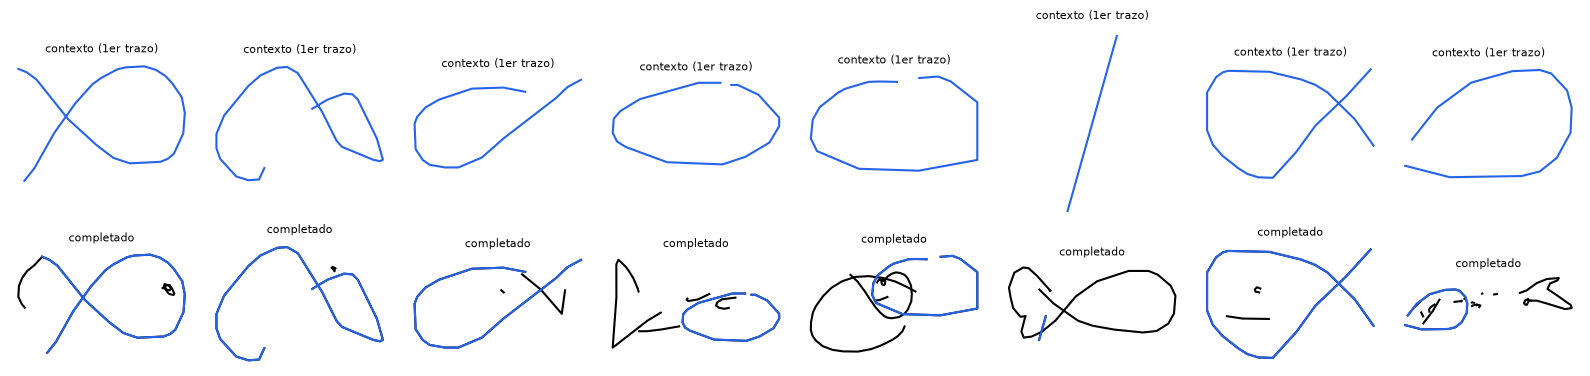

In [25]:
@torch.no_grad()
def complete(model, sketch5_norm, n_context, temperature=TEMPERATURE, seed=0):
    model.eval()
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    ctx = torch.as_tensor(np.vstack([START_TOKEN, sketch5_norm[:n_context]]), device=DEVICE)[None]
    raw_gmm, pen_logits, state = model(ctx)
    pts = [p for p in sketch5_norm[:n_context]]
    for _ in range(MAX_POINTS - n_context):
        dxdy = gmm_sample(gmm_params(raw_gmm[:, -1], model.n_mix), temperature, g)[0]
        pen = int(torch.multinomial(F.softmax(pen_logits[0, -1] - LOG_W, -1), 1, generator=g))
        p = np.zeros(5, dtype=np.float32)
        p[0:2], p[2 + pen] = dxdy.cpu().numpy(), 1.0
        pts.append(p)
        if pen == 2:
            break
        raw_gmm, pen_logits, state = model(torch.as_tensor(p, device=DEVICE)[None, None], state)
    return to_stroke3(denormalize(np.array(pts), SCALE))


multi_stroke = [i for i, s in enumerate(valid5) if s[:, 3].sum() >= 2]        # al menos 2 trazos
fig, axes = plt.subplots(2, 8, figsize=(16, 4.2))
for j, idx in enumerate(multi_stroke[:8]):
    s5 = normalize(valid5[idx], SCALE)
    first_stroke = int(np.argmax(s5[:, 3] == 1)) + 1                     # puntos del primer trazo
    draw_sketch(axes[0, j], to_stroke3(valid5[idx][:first_stroke]), lw=1.5, color="#2563eb")
    axes[0, j].set_title("contexto (1er trazo)", fontsize=8)
    done = complete(model, s5, first_stroke, seed=j)
    draw_sketch(axes[1, j], done, lw=1.5)
    draw_sketch(axes[1, j], to_stroke3(valid5[idx][:first_stroke]), lw=1.5, color="#2563eb")
    axes[1, j].set_title("completado", fontsize=8)
plt.tight_layout()
plt.show()

Los resultados de la completación son irregulares. En 3 o 4 de los 8 casos el modelo continúa el boceto de forma coherente: cuando el primer trazo ya es el contorno del pez, agrega detalles como el ojo, la boca o la cola. En los demás, los trazos nuevos quedan desplazados respecto al contexto, se superponen con él o aparecen como marcas sueltas. La parte más difícil es decidir dónde empieza el siguiente trazo después de levantar el lápiz, que es la predicción más incierta del modelo, y algunos contextos (una línea recta o un óvalo abierto) son poco comunes en los datos de entrenamiento. Además, cada boceto se completa con una sola muestra. Esta tarea no forma parte de las métricas del proyecto, pero muestra una limitación del modelo que se discute en las conclusiones.

## 10. Conclusiones

### Resultados

Sobre el conjunto de prueba (2.000 bocetos y 76.135 puntos reales, con predicción a un paso), el modelo obtuvo un MSE
de 0.4560 en coordenadas normalizadas (882.5 px²), un F1 macro de 0.6702 y una pérdida compuesta de 1.5250. Un modelo
trivial que siempre predice Δ = 0 y "lápiz abajo" obtiene un MSE de 0.993 y un F1 macro de 0.314. Es decir, el modelo
reduce el error cuadrático a menos de la mitad (explica cerca del 54 % de la varianza del siguiente desplazamiento) y
más que duplica el F1 macro.

El F1 por clase fue de 0.92 para lápiz abajo, 0.49 para fin de trazo y 0.60 para fin de dibujo. El fin de dibujo se
detecta con un recall alto (0.92), pero con precisión moderada: en los bocetos reales, situaciones muy parecidas a
veces terminan el dibujo y a veces continúan con un detalle como el ojo o una aleta. El fin de trazo es el estado más
difícil, porque en muchos puntos el lápiz podría levantarse o seguir. Calibrar los umbrales en validación casi no
cambió el F1 (0.6781), lo que indica que los pesos de clase ya ubicaron bien la frontera de decisión.

El MSE en Δx (1170 px²) es mayor que en Δy (595 px²) porque los peces son más anchos que altos (σx ≈ 52 px y
σy ≈ 35 px); en unidades normalizadas el error de los dos ejes es similar.

En cuanto a la generación, los bocetos se reconocen como peces: un contorno ovalado con la cola en forma de "α",
muchas veces con ojo y a veces con aletas. Con la corrección de priors su longitud promedio (37.2 puntos) coincide con
la de los reales (36.9), aunque tienen algo más de trazos (3.56 frente a 3.17). La temperatura controla el balance
entre limpieza y variedad: con τ entre 0.1 y 0.3 los contornos salen limpios y con τ = 1 son más variados pero más
ruidosos. En cambio, la prueba de completar bocetos a partir de un primer trazo real dio resultados irregulares: el modelo
agrega detalles coherentes cuando el primer trazo ya es el contorno del pez, pero con contextos menos comunes los
trazos nuevos quedan desplazados o superpuestos.

### Sobreajuste

Para evitarlo se usó un conjunto de validación para todas las decisiones (el de prueba solo se usó al final), early
stopping sobre la pérdida de validación (mejor época 48 de 56), dropout de 0.3 (elegido en la ronda 3 porque con 0.1 el
modelo sobreajustaba), reducción de la tasa de aprendizaje cuando la validación se estancaba, recorte de gradientes y
un modelo de tamaño moderado (cerca de 1.4 millones de parámetros para 16.000 bocetos).

En las curvas, las pérdidas de entrenamiento y validación bajan juntas hasta cerca de la época 30. Después, la de
entrenamiento sigue bajando mientras la de validación se estabiliza, y el early stopping conserva el mejor punto. Queda
una diferencia moderada entre entrenamiento y validación (pérdida 1.146 frente a 1.538, MSE 0.370 frente a 0.448, F1
0.713 frente a 0.670), pero validación y prueba son prácticamente iguales (pérdida 1.538 frente a 1.525, MSE 0.448
frente a 0.456, F1 0.670 en ambos). El modelo generaliza a bocetos que no vio durante el entrenamiento y la estimación
hecha con validación fue confiable.

### Aprendizajes de la experimentación

1. Optimizar directamente la métrica no fue suficiente: la cabeza MSE gana en MSE pero colapsa al generar. La mezcla
   de Gaussianas con el término MSE auxiliar logra una buena predicción puntual y, al mismo tiempo, bocetos variados.
2. El contexto importa. Con ventana fija, más contexto siempre mejoró los resultados; el mejor modelo combina contexto
   local explícito (convoluciones causales) con la memoria de todo el boceto (LSTM).
3. Comparar contra otras familias ayudó a encontrar la mejora. Que la TCN le ganara a la LSTM en la ronda 1 mostró qué
   le faltaba al modelo recurrente y llevó a agregar el frente convolucional, en lugar de solo aumentar el tamaño de la
   LSTM.
4. El desbalance de clases se manejó en dos partes: pesos de clase en la entropía cruzada para mejorar el F1, y
   corrección de priors al muestrear para no afectar la generación.
5. Lo que más importa depende del entrenamiento: con pocas épocas la tasa de aprendizaje fue el hiperparámetro más
   influyente, y con entrenamiento largo la regularización (dropout) pasó a ser la clave.

### Limitaciones y trabajo futuro

- Las métricas a un paso, con teacher forcing, no miden directamente la generación autorregresiva, donde los errores
  se acumulan. Por eso algunos bocetos generados tienen trazos de más o quedan abiertos. Se podría probar scheduled
  sampling.
- El fin de trazo es ambiguo por naturaleza y limita el F1 macro. Además, el MSE sobre un objetivo con varias
  respuestas posibles tiene un límite que ninguna predicción puntual puede superar.
- El modelo no es condicional: no permite elegir qué tipo de pez dibujar. La versión VAE de Sketch-RNN, con un
  codificador bidireccional y una variable latente, permitiría condicionar, reconstruir e interpolar bocetos.
- Por limitaciones de cómputo (CPU), cada configuración se entrenó con una sola semilla y las rondas cortas usaron 15
  épocas, lo que puede perjudicar a modelos que convergen más lento, como el Transformer. Con GPU valdría la pena
  repetir las mejores configuraciones con varias semillas y probar una LSTM con layer normalization y recurrent
  dropout, como en Sketch-RNN.
- La completación de bocetos funciona de forma irregular. El modelo se entrenó para dibujar desde el punto inicial y no
  para continuar un trazo dado; la posición donde empieza cada trazo nuevo es su predicción más incierta. Un modelo
  condicional, como el VAE de Sketch-RNN, o generar varias muestras por contexto y quedarse con la más probable,
  podrían mejorar este punto.
- Los datos están simplificados con RDP y limitados a 16.000 bocetos de entrenamiento.

### Repositorio

El código de los experimentos, los resultados de las 39 configuraciones (métricas, historial por época y bocetos
generados por cada corrida) y este notebook están en el repositorio del equipo:

https://github.com/jcrkboy/mp1_equipo_21/tree/aporte/juan-rodriguez-fish/aportes/juan_rodriguez/sketchrnn_fish